# Notebook 3: History matching, choose the 10 best cases

**Role:** history matching (Step 2-3 of the workflow). **Reads:** `hist_match_input/` (made by `notebook2_proxy_model.ipynb`). **Writes:** `hist_match_output/`.

## What this notebook does

```
 simulated curves of the 100 cases  +  proxy (Elton's model, improved)  +  observed history
                          |
        [0] align to the matching window, oil + water cumulative, scale by the final observed value
                          |
          +---------------+----------------+
          |                                |
   [A] SCORE THE 100 CASES          [B] BAYESIAN MCMC
   real simulator curves            sample the 4 parameters (emcee) with the proxy
          |                                |
          +---------------+----------------+
                          |
        [C] HYBRID CHOICE OF 10: candidates = 100 cases + posterior sets
            rule out (implausibility > 3) -> k-means 10 clusters -> best per cluster,
            a simulated case wins unless a new set is better by more than the proxy error
                          |
        [D] checks: direct sampling, implausibility map, global search, oil-water trade-off,
            hold-out, scorecard, recovery test on known cases; CSV + figures
```

It merges the team's two drafts:

| Part | From | Change |
|---|---|---|
| Score, window, likelihood, MCMC, checks 10b-10g | Yi Siang v1 / v2 | The stand-in proxy is replaced by the team's proxy (Elton's model, improved: notebook 2, section 6b). Prior = train range without padding |
| Choosing the 10 from the posterior with k-means | Zi Yang (and Elton) | Clustering over everything the history does not rule out, not only the best 100 points |
| Simulated cases preferred | New (team decision) | A new parameter set replaces a simulated case only when it is better by more than the proxy's own error |

## Key design choices

| Choice | Reason |
|---|---|
| Match **cumulative oil and water**, 37 dates from 1999-01-01 | Gas is about 0.3633 x oil in every case, so it would count oil twice. The 4 quarters before production are zero everywhere. Cumulatives avoid the rate-convention mismatch between the history and the cases |
| Scale by the observed value at 2008-01-01 | Oil and water count equally. Scores read as a share of the final cumulative (0.005 = 0.5 %) |
| Prior = **train range** of the 4 parameters, no padding | The proxy was trained there. Elton's search went 5 % beyond and its best sets sat on that outer edge (aquifer 207 > 199.8), where the proxy extrapolates |
| Noise level **sampled**, plus the proxy error from notebook 2 | The history has no stated error. A weaker proxy gives a wider, more honest posterior |
| AR(1) residual correlation | Cumulative errors are smooth in time. Treating them as independent makes the posterior too narrow |
| **Hybrid** choice of the 10 (team decision) | Simulated cases have real curves; new sets can fill parts of the good region that no case covers. Clustering gives 10 *different* matches, not 10 near-copies |
| Test cases 86-100 are candidates (team decision) | The proxy is frozen in notebook 2; the cases are simulator results like any other |

In [1]:
import os, warnings, time, json, sys
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count()))   # silences a joblib core-count warning (k-means)
from dataclasses import dataclass, field, replace
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import emcee
import torch
from scipy.optimize import differential_evolution
from scipy.stats import spearmanr
from sklearn.cluster import KMeans

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="Could not find the number of physical cores")   # joblib on Windows, harmless
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_after_engineering").exists())
sys.path.insert(0, str(ROOT / "src"))
import proxy_lib as pl

DATA_DIR = ROOT / "data_after_engineering"     # engineered data (notebook 1)
INPUT_DIR = ROOT / "hist_match_input"          # ONE input folder: written by notebook 2
HM_DIR = ROOT / "hist_match_output"            # ONE output folder: the 10 cases, scores, posterior, figures
FIG_DIR = HM_DIR / "figs"
HM_DIR.mkdir(exist_ok=True); FIG_DIR.mkdir(exist_ok=True)
torch.set_num_threads(1)                       # small batches: one thread is fastest

PARAMS = pl.PARAMS
ALL_Q = ("gas_cum", "oil_cum", "water_cum")
TAG = "real"


@dataclass
class HMConfig:
    # All settings of the pipeline in one place.
    match_quantities: tuple = ("oil_cum", "water_cum")  # gas left out on purpose (= 0.3633 x oil)
    rho: object = "auto"            # AR(1) correlation of residuals: "auto" or a number in [0, 0.99]
    n_ensembles: int = 4            # independent emcee ensembles
    n_walkers: int = 16             # walkers per ensemble
    n_steps: int = 12000            # steps per walker
    burn_frac: float = 0.5          # share of steps thrown away
    prior: str = "uniform"          # "uniform" or "triangular" (mode at mid-range)
    prior_pad: float = 0.0          # 0 = exactly the train range (the proxy's valid range)
    log_sigma_range: tuple = (float(np.log(1e-4)), float(np.log(0.1)))   # prior on the noise level (relative)
    n_top: int = 10
    impl_sd: float = 0.01           # PROVISIONAL observation + model error for implausibility (share of final)
    impl_cut: float = 3.0           # ruled out above this implausibility
    n_post_candidates: int = 4000   # posterior samples offered as new candidate sets
    min_sep: float = 0.05           # v1 near-copy rule (used for the "simulated only" comparison list)
    accept_nrmse: float = 0.01      # PROVISIONAL accept level for the plots (1 % of the final cumulative)
    seed: int = 0


CFG = HMConfig()
print("root:", ROOT, "| emcee", emcee.__version__, "| torch", torch.__version__)

root: C:\Users\Yi Siang\Documents\UM\dwc_team_what_repo | emcee 3.1.6 | torch 2.13.0+cpu


## 1. Data containers and loaders (from v1)

`CaseSet` holds the curves of many cases. `History` holds the observed field history. Only the dates that overlap the history are used for matching.

In [2]:
@dataclass
class CaseSet:
    # Production time series of several cases.
    case_ids: np.ndarray                 # (n,)
    dates: np.ndarray                    # (T,) datetime64[D], increasing
    curves: dict                         # name -> (n, T) cumulative values, e.g. "oil_cum"
    params: pd.DataFrame = None          # index = case_id, columns = PARAMS


@dataclass
class History:
    dates: np.ndarray                    # (T,) datetime64[D]
    curves: dict                         # name -> (T,)


def caseset_from_long(df, params=None):
    # df has columns case_id, date and any of gas_cum, oil_cum, water_cum (one row per case and date).
    df = df.copy()
    df["date"] = pd.to_datetime(df["date"])
    qs = [q for q in ALL_Q if q in df.columns]
    ids = np.sort(df["case_id"].unique())
    dates = np.sort(df["date"].unique())
    curves = {}
    for q in qs:
        piv = df.pivot(index="case_id", columns="date", values=q).loc[ids, dates]
        if piv.isna().any().any():
            raise ValueError(f"{q}: not every case has a value on every date")
        curves[q] = piv.to_numpy(float)
    return CaseSet(ids, dates.astype("datetime64[D]"), curves, params)


def subset(cs, ids):
    keep = np.isin(cs.case_ids, ids)
    return CaseSet(cs.case_ids[keep], cs.dates, {q: a[keep] for q, a in cs.curves.items()},
                   None if cs.params is None else cs.params.loc[cs.case_ids[keep]])


def load_history(path=DATA_DIR / "history_observed.csv"):
    h = pd.read_csv(path, parse_dates=["date"])
    return History(h["date"].values.astype("datetime64[D]"), {q: h[q].to_numpy(float) for q in ALL_Q if q in h.columns})


def load_bounds(path=DATA_DIR / "param_bounds.csv"):
    return pd.read_csv(path).set_index("parameter").loc[PARAMS]

## 2. Preprocessing: the matching window (from v1)

* The window starts at the first date where the history has oil: **1999-01-01**, 37 dates to 2008-01-01.
* Each quantity is scaled by the observed value on the last window date.

In [3]:
@dataclass
class Window:
    case_ids: np.ndarray
    dates: np.ndarray            # (Tw,) the matching dates
    quantities: list
    Yc: np.ndarray               # (n, Tw, Q) cumulative curves in real units
    Yh: np.ndarray               # (Tw, Q) observed
    scale: np.ndarray            # (Q,) observed value on the last window date


def check_inputs(cs, hist, quantities):
    for q in quantities:
        if q not in cs.curves:
            raise ValueError(f"Curves are missing '{q}'. Found: {list(cs.curves)}")
        if q not in hist.curves:
            raise ValueError(f"History is missing '{q}'")
        a = cs.curves[q]
        if a.shape != (len(cs.case_ids), len(cs.dates)):
            raise ValueError(f"{q}: shape {a.shape} does not match (n_cases, n_dates)")
        if not np.isfinite(a).all():
            raise ValueError(f"{q}: contains NaN or infinite values")
    if not (np.diff(cs.dates.astype("int64")) > 0).all():
        raise ValueError("Dates must be strictly increasing")
    if len(np.unique(cs.case_ids)) != len(cs.case_ids):
        raise ValueError("case_id values must be unique")


def align_window(cs, hist, quantities):
    quantities = list(quantities)
    check_inputs(cs, hist, quantities)
    first = int(np.argmax(hist.curves[quantities[0]] > 0))
    wd = hist.dates[first:]
    if wd[0] < cs.dates[0] or wd[-1] > cs.dates[-1]:
        raise ValueError(f"Curves span {cs.dates[0]} to {cs.dates[-1]} but the window is {wd[0]} to {wd[-1]}")
    exact = np.isin(wd, cs.dates)
    Yc = np.empty((len(cs.case_ids), len(wd), len(quantities)))
    for j, q in enumerate(quantities):
        A = cs.curves[q]
        if exact.all():
            Yc[:, :, j] = A[:, np.searchsorted(cs.dates, wd)]
        else:                                           # interpolate cumulative values onto the history dates
            dc = (cs.dates - cs.dates[0]).astype(float)
            dw = (wd - cs.dates[0]).astype(float)
            for i in range(len(cs.case_ids)):
                Yc[i, :, j] = np.interp(dw, dc, A[i])
    Yh = np.column_stack([hist.curves[q][first:] for q in quantities])
    scale = Yh[-1].copy()
    if (scale <= 0).any():
        raise ValueError("Observed history is zero on the last date; cannot scale")
    return Window(cs.case_ids, wd, quantities, Yc, Yh, scale)

## 3. Mismatch metrics (method A, from v1)

For each case, the residual is `(predicted - observed) / scale`: a share of the final cumulative.

| Column | Meaning |
|---|---|
| `nrmse_oil`, `nrmse_water` | Root-mean-square residual over the window |
| **`score`** | **Headline mismatch** = sqrt(mean of the squared NRMSEs of oil and water). Lower is better |
| `max_rel_err` | Worst single residual (any quantity, any date) |
| `err_final_oil`, `err_final_water` | Signed residual on the last date (positive = predicted too high) |
| `I_max` | Implausibility: worst residual at 4 dates (25/50/75/100 % of the window) in error units. Above 3 = ruled out |

In [4]:
def whiten(R, rho):
    # AR(1) pre-whitening along the time axis (axis -2). rho = 0 returns R unchanged.
    E = np.empty_like(R)
    E[..., 0, :] = np.sqrt(1.0 - rho ** 2) * R[..., 0, :]
    E[..., 1:, :] = R[..., 1:, :] - rho * R[..., :-1, :]
    return E


def estimate_rho(R, cap=0.95):
    # Lag-1 autocorrelation of residuals, pooled. R has shape (k, T, Q).
    num = (R[:, 1:, :] * R[:, :-1, :]).sum()
    den = (R ** 2).sum()
    return float(np.clip(num / den, 0.0, cap)) if den > 0 else 0.0


def _impl_idx(T):
    return np.unique([T // 4, T // 2, (3 * T) // 4, T - 1])


def curve_metrics(Yc, win, sd=None, sigma_proxy=None):
    # Scores of any curves (n, Tw, Q) against the history. Returns a DataFrame (no index).
    R = (Yc - win.Yh[None]) / win.scale
    names = [q.replace("_cum", "") for q in win.quantities]
    nr = np.sqrt((R ** 2).mean(axis=1))
    df = pd.DataFrame({f"nrmse_{nm}": nr[:, j] for j, nm in enumerate(names)})
    df["score"] = np.sqrt((nr ** 2).mean(axis=1))
    df["max_rel_err"] = np.abs(R).max(axis=(1, 2))
    for j, nm in enumerate(names):
        df[f"err_final_{nm}"] = R[:, -1, j]
    if sd is not None:
        sp = np.zeros(len(names)) if sigma_proxy is None else np.asarray(sigma_proxy)
        idx = _impl_idx(R.shape[1])
        df["I_max"] = (np.abs(R[:, idx, :]) / np.sqrt(sd ** 2 + sp ** 2)).max(axis=(1, 2))
    return df


def score_cases(win, sd):
    # Method A on supplied cases: one row per case, indexed by case_id.
    df = curve_metrics(win.Yc, win, sd).set_index(pd.Index(win.case_ids, name="case_id"))
    df["rank_A"] = df["score"].rank(method="first").astype(int)
    return df


def misfit_elton(C, y_hist):
    # Elton's objective, for comparison only: 3 phases x 41 dates, scaled by the final observed value.
    d = (C - y_hist[None]) / y_hist[-1][None, None]
    return np.sqrt((d ** 2).mean(axis=(1, 2)))

## 4. Inputs from the proxy team (`hist_match_input/`)

| File | Use here |
|---|---|
| `simulated.csv` | Simulator curves of the 100 cases: **method A** and the simulated candidates |
| `predictions.csv` | Proxy curves of the same cases: consistency check of the proxy |
| `case_params.csv` | The 4 parameters of every case |
| `cumulative_model.pt`, `proxy_meta.json` | The proxy, loaded with `proxy_lib.CumulativeProxy`; `sigma_proxy` (validation error, share of final) |

In [5]:
CASE_PARAMS = pd.read_csv(INPUT_DIR / "case_params.csv").set_index("case_id")
SPLIT = CASE_PARAMS["split"]
SIM = caseset_from_long(pd.read_csv(INPUT_DIR / "simulated.csv").drop(columns="split"), params=CASE_PARAMS[PARAMS])
PRED = caseset_from_long(pd.read_csv(INPUT_DIR / "predictions.csv").drop(columns="split"), params=CASE_PARAMS[PARAMS])
HISTORY = load_history()
BOUNDS = load_bounds()
META = json.loads((INPUT_DIR / "proxy_meta.json").read_text())

WIN = align_window(SIM, HISTORY, CFG.match_quantities)
PROXY = pl.CumulativeProxy(INPUT_DIR, WIN.dates, CFG.match_quantities)
assert np.allclose(PROXY.lo, BOUNDS["train_min"]) and np.allclose(PROXY.hi, BOUNDS["train_max"]), "bounds differ"
print(f"{len(SIM.case_ids)} simulated cases; window {WIN.dates[0]} to {WIN.dates[-1]} ({len(WIN.dates)} dates); "
      f"quantities {WIN.quantities}")
print(f"proxy: {META['made_by']} ({META['created']}), config {META['config']['feature_set']} "
      f"{META['config']['hidden']}, sha256 {META['model_sha256'][:12]}...")
print("sigma_proxy (validation, share of final):", {q: round(float(v), 5) for q, v in zip(CFG.match_quantities, PROXY.sigma_proxy)})

# consistency: the proxy reproduces predictions.csv, and ranks the cases like the simulator
WP = align_window(PRED, HISTORY, CFG.match_quantities)
assert np.allclose(PROXY(SIM.params.loc[SIM.case_ids].to_numpy()), WP.Yc, rtol=1e-6, atol=1e-6 * WIN.scale.max())
s_sim, s_prx = score_cases(WIN, CFG.impl_sd)["score"], score_cases(WP, CFG.impl_sd)["score"]
for sp in ["train", "validation", "test"]:
    ids = SPLIT.index[SPLIT == sp]
    print(f"  {sp:<10} score from proxy vs simulator: Spearman {spearmanr(s_sim[ids], s_prx[ids])[0]:.3f}, "
          f"mean |diff| {(s_sim[ids] - s_prx[ids]).abs().mean() * 100:.3f} %")

100 simulated cases; window 1999-01-01 to 2008-01-01 (37 dates); quantities ['oil_cum', 'water_cum']
proxy: notebook2_proxy_model.ipynb (2026-10-15 02:55), config p4g8 [128, 128], sha256 df97f078e5e4...
sigma_proxy (validation, share of final): {'oil_cum': 0.00074, 'water_cum': 0.00138}
  train      score from proxy vs simulator: Spearman 1.000, mean |diff| 0.054 %
  validation score from proxy vs simulator: Spearman 1.000, mean |diff| 0.055 %
  test       score from proxy vs simulator: Spearman 1.000, mean |diff| 0.047 %


## 5. Bayesian model and MCMC (method B, from v1)

Model: `observation = proxy(theta) + noise`, Gaussian noise.

* **Unknowns:** the 4 parameters and one noise level per matched quantity (6 numbers). Noise levels are sampled on a log scale.
* **Prior:** uniform on the train range of the parameters (no padding).
* **Likelihood:** Gaussian on the scaled residuals, AR(1) correlation `rho`. Effective variance = sampled noise^2 + `sigma_proxy`^2.
* **Sampler:** `emcee` (affine-invariant ensemble). 4 independent ensembles x 16 walkers, started at random points across the prior box. First half dropped.
* **Checks:** acceptance rate, autocorrelation time, effective sample size, split R-hat (below 1.1).

In [6]:
class LogPosterior:
    # Vectorised log-posterior. A row of X is [theta (4), log sigma (one per matched quantity)].

    def __init__(self, proxy, win, rho, cfg, bounds):
        self.proxy, self.win, self.rho, self.cfg = proxy, win, rho, cfg
        rng_ = (bounds["train_max"] - bounds["train_min"]).to_numpy()
        self.lo = bounds["train_min"].to_numpy() - cfg.prior_pad * rng_
        self.hi = bounds["train_max"].to_numpy() + cfg.prior_pad * rng_
        self.Q = len(win.quantities)
        self.ndim = 4 + self.Q
        sp = getattr(proxy, "sigma_proxy", None)
        self.sigma_proxy = np.zeros(self.Q) if sp is None else np.asarray(sp, float)

    def log_prior(self, X):
        th, ls = X[:, :4], X[:, 4:]
        a, b = self.cfg.log_sigma_range
        ok = ((th >= self.lo) & (th <= self.hi)).all(1) & ((ls >= a) & (ls <= b)).all(1)
        lp = np.where(ok, 0.0, -np.inf)
        if self.cfg.prior == "triangular":
            u = np.clip((th - self.lo) / (self.hi - self.lo), 1e-12, 1 - 1e-12)
            lp = lp + np.where(ok, np.log(np.maximum(1 - np.abs(2 * u - 1), 1e-12)).sum(1), 0.0)
        return lp

    def log_like(self, R, ls):
        n = R.shape[1]
        s2 = np.exp(2 * ls) + self.sigma_proxy ** 2
        E = whiten(R, self.rho)
        rss = (E ** 2).sum(axis=1)
        c = 1.0 - self.rho ** 2
        return (-0.5 * n * np.log(s2) - 0.5 * (n - 1) * np.log(c) - rss / (2 * s2 * c)).sum(1)

    def __call__(self, X):
        X = np.atleast_2d(X)
        out = np.full(len(X), -np.inf)
        lp = self.log_prior(X)
        ok = np.isfinite(lp)
        if ok.any():
            R = (self.win.Yh[None] - self.proxy(X[ok, :4])) / self.win.scale
            ll = self.log_like(R, X[ok, 4:])
            out[ok] = np.where(np.isfinite(ll), lp[ok] + ll, -np.inf)
        return out


def split_rhat(c):
    # Split R-hat. c has shape (steps, chains, dims).
    n = c.shape[0] // 2
    s = np.concatenate([c[:n], c[n:2 * n]], axis=1)
    W = s.var(axis=0, ddof=1).mean(axis=0)
    B = n * s.mean(axis=0).var(axis=0, ddof=1)
    return np.sqrt(((n - 1) / n * W + B / n) / W)


def run_mcmc(logpost, cfg, seed):
    rs = np.random.RandomState(seed)
    chains, logps, accs, taus = [], [], [], []
    a, b = cfg.log_sigma_range
    for e in range(cfg.n_ensembles):
        p0 = np.empty((cfg.n_walkers, logpost.ndim))
        p0[:, :4] = logpost.lo + rs.rand(cfg.n_walkers, 4) * (logpost.hi - logpost.lo)       # spread over the prior box
        p0[:, 4:] = np.log(10.0 ** rs.uniform(-3.5, -1.7, (cfg.n_walkers, logpost.Q)))       # noise 0.03 % to 2 %
        p0[:, 4:] = np.clip(p0[:, 4:], a + 1e-6, b - 1e-6)
        s = emcee.EnsembleSampler(cfg.n_walkers, logpost.ndim, logpost, vectorize=True)
        s.random_state = np.random.RandomState(seed * 1000 + e).get_state()
        s.run_mcmc(p0, cfg.n_steps, progress=False)
        chains.append(s.get_chain())
        logps.append(s.get_log_prob())
        accs.append(float(np.mean(s.acceptance_fraction)))
        burn = int(cfg.burn_frac * cfg.n_steps)
        taus.append(emcee.autocorr.integrated_time(s.get_chain(discard=burn), tol=0, quiet=True))
    return np.concatenate(chains, axis=1), np.concatenate(logps, axis=1), accs, np.array(taus)


def posterior_summary(flat, lo, hi, q_names):
    rows = []
    names = PARAMS + [f"sigma_{q.replace('_cum', '')}" for q in q_names]
    for j, nm in enumerate(names):
        x = flat[:, j] if j < 4 else np.exp(flat[:, j])
        prior_sd = (hi[j] - lo[j]) / np.sqrt(12) if j < 4 else np.nan
        rows.append({"parameter": nm, "mean": x.mean(), "sd": x.std(), "p05": np.percentile(x, 5),
                     "p50": np.percentile(x, 50), "p95": np.percentile(x, 95),
                     "sd_ratio_vs_prior": x.std() / prior_sd if j < 4 else np.nan})
    s = pd.DataFrame(rows).set_index("parameter")
    s["well_determined"] = np.where(s["sd_ratio_vs_prior"] < 0.5, "yes",
                                    np.where(s["sd_ratio_vs_prior"].isna(), "", "no"))
    return s

## 6. The pipeline function: score, sample

`run_history_matching` does steps [0], [A] and [B] in one call. It is also used by the recovery test (section 11) with fake histories.

In [7]:
@dataclass
class HMResult:
    cfg: HMConfig
    cs: CaseSet
    hist: History
    win: Window
    rho: float
    scores: pd.DataFrame                  # every supplied case: metrics and rank
    posterior: dict
    proxy: object
    notes: list = field(default_factory=list)


def nrmse_vs(pred, win):
    R = (pred - win.Yh) / win.scale
    return float(np.sqrt((np.sqrt((R ** 2).mean(axis=0)) ** 2).mean()))


def run_history_matching(cs, hist, cfg, proxy, bounds=None, true_theta=None, verbose=True):
    bounds = BOUNDS if bounds is None else bounds
    t0 = time.time()
    log = []
    say = (lambda s: (print(s), log.append(s))) if verbose else (lambda s: log.append(s))
    win = align_window(cs, hist, cfg.match_quantities)
    say(f"[0] {len(win.case_ids)} case(s); window {win.dates[0]} to {win.dates[-1]} ({len(win.dates)} dates)")

    # ---- Method A: score every supplied case (real simulator curves)
    R_raw = (win.Yc - win.Yh[None]) / win.scale
    if cfg.rho == "auto":
        best = np.argsort(np.sqrt((R_raw ** 2).mean(axis=(1, 2))))[:min(5, len(R_raw))]
        rho = estimate_rho(R_raw[best])
    else:
        rho = float(cfg.rho)
    scores = score_cases(win, cfg.impl_sd)
    say(f"[A] residual correlation rho = {rho:.2f}; best case {scores['score'].idxmin()} with score "
        f"{scores['score'].min():.4f}; {int((scores['I_max'] <= cfg.impl_cut).sum())} case(s) not ruled out")

    # ---- Method B: MCMC with the proxy
    lp = LogPosterior(proxy, win, rho, cfg, bounds)
    chain, logp, accs, taus = run_mcmc(lp, cfg, cfg.seed)
    burn = int(cfg.burn_frac * cfg.n_steps)
    postc = chain[burn:]
    rhat = split_rhat(postc)
    tau = taus.mean(axis=0)
    flat = postc.reshape(-1, lp.ndim)
    flat_lp = logp[burn:].reshape(-1)
    ess = len(flat) / max(1.0, float(tau.max()))
    names = PARAMS + [f"log_sigma_{q.replace('_cum', '')}" for q in win.quantities]
    diag = pd.DataFrame({"r_hat": rhat, "autocorr_time": tau}, index=pd.Index(names, name="parameter"))
    summary = posterior_summary(flat, lp.lo, lp.hi, win.quantities)
    # distance of every supplied case to the posterior (Mahalanobis, 0-1 scaled parameter space), for information
    lo_t, hi_t = bounds["train_min"].to_numpy(), bounds["train_max"].to_numpy()
    zs = (flat[:, :4] - lo_t) / (hi_t - lo_t)
    mu, cov = zs.mean(0), np.cov(zs.T) + 1e-6 * np.eye(4)
    dz = ((cs.params.loc[win.case_ids, PARAMS].to_numpy() - lo_t) / (hi_t - lo_t)) - mu
    scores["post_dist"] = np.sqrt(np.einsum("ij,jk,ik->i", dz, np.linalg.inv(cov), dz))
    th_mean, th_map = flat[:, :4].mean(0), flat[np.argmax(flat_lp), :4]
    draws = flat[np.random.default_rng(cfg.seed).choice(len(flat), 300, replace=False), :4]
    post = dict(chain=chain, logp=logp, burn=burn, flat=flat, flat_lp=flat_lp, diag=diag, summary=summary,
                ess=ess, acc=accs, mean=th_mean, map=th_map, band=np.percentile(proxy(draws), [10, 50, 90], axis=0),
                nrmse_mean=nrmse_vs(proxy(th_mean[None])[0], win), nrmse_map=nrmse_vs(proxy(th_map[None])[0], win),
                sigma_proxy=lp.sigma_proxy, lo=lp.lo, hi=lp.hi, true_theta=true_theta)
    say(f"[B] MCMC: {cfg.n_ensembles} ensembles x {cfg.n_walkers} walkers x {cfg.n_steps} steps; "
        f"acceptance {np.mean(accs):.2f}; max R-hat {rhat.max():.3f}; max autocorr. time {tau.max():.0f}; "
        f"effective samples ~{ess:.0f}")
    say(f"[B] posterior-mean curve score {post['nrmse_mean']:.4f}; MAP curve score {post['nrmse_map']:.4f}")
    if rhat.max() > 1.1:
        say("[B] WARNING: R-hat above 1.1. Run longer (cfg.n_steps) before trusting the posterior.")
    say(f"done in {time.time() - t0:.1f} s")
    return HMResult(cfg, cs, hist, win, rho, scores, post, proxy, log)

## 7. Hybrid choice of the 10 (team decision)

1. **Candidates.** The 100 simulated cases (real curves) and `n_post_candidates` distinct posterior samples (curves from the proxy). Every candidate gets the same scores.
2. **Rule out** every candidate with implausibility `I_max > 3`. For a simulated case the error is `impl_sd` only; for a new set the proxy error is added: `sqrt(impl_sd^2 + sigma_proxy^2)`.
3. **Cluster** the remaining candidates into 10 groups with k-means in the 0-1 scaled parameter space. Each group is a different way to explain the history.
4. **One per cluster.** The lowest-score candidate of the group, with a preference: the best **simulated** case of the group wins unless the best **new set** is better by more than the proxy error `eps` (in score units). Two scores closer than `eps` cannot be told apart, so the simulated curve, which is exact, is preferred.
5. Rank the 10 by score.

This fixes the weak point of Elton's choice: he clustered only the best 100 points of a local search, so his 10 were nearly identical (2028 oil within 0.3 %).

In [8]:
def scaled(theta, bounds=None):
    bounds = BOUNDS if bounds is None else bounds
    lo, hi = bounds["train_min"].to_numpy(), bounds["train_max"].to_numpy()
    return (np.asarray(theta) - lo) / (hi - lo)


def build_candidates(res, cfg, seed=0):
    win, sp = res.win, res.posterior["sigma_proxy"]
    sim_theta = res.cs.params.loc[win.case_ids, PARAMS].to_numpy()
    sim = curve_metrics(win.Yc, win, cfg.impl_sd)
    sim.insert(0, "source", "simulated")
    sim.insert(0, "cand_id", [f"case_{c}" for c in win.case_ids])
    sim.insert(2, "case_id", win.case_ids.astype(float))
    sim["proxy_score"] = curve_metrics(res.proxy(sim_theta), win)["score"].to_numpy()
    sim[PARAMS] = sim_theta
    uniq = np.unique(res.posterior["flat"][:, :4], axis=0)                     # rejected moves repeat a row
    pick = np.random.default_rng(seed).choice(len(uniq), min(cfg.n_post_candidates, len(uniq)), replace=False)
    th = uniq[np.sort(pick)]
    new = curve_metrics(res.proxy(th), win, cfg.impl_sd, sp)
    new.insert(0, "source", "new_set")
    new.insert(0, "cand_id", [f"set_{k:04d}" for k in range(len(th))])
    new.insert(2, "case_id", np.nan)
    new["proxy_score"] = new["score"]
    new[PARAMS] = th
    cand = pd.concat([sim, new], ignore_index=True)
    cand["not_ruled_out"] = cand["I_max"] <= cfg.impl_cut
    return cand.set_index("cand_id")


def hybrid_select(cand, cfg, eps, seed=0, bounds=None):
    note = ""
    acc = cand[cand["not_ruled_out"]].copy()
    if len(acc) < 5 * cfg.n_top:                         # too few left to cluster: fall back to the best 20 %
        acc = cand.nsmallest(max(5 * cfg.n_top, int(0.2 * len(cand))), "score").copy()
        note = f"only {int(cand['not_ruled_out'].sum())} candidates not ruled out: clustered the best {len(acc)} by score"
    Z = scaled(acc[PARAMS].to_numpy(), bounds)
    km = KMeans(cfg.n_top, n_init=10, random_state=seed).fit(Z)
    acc["cluster"] = km.labels_
    picks = []
    for c in range(cfg.n_top):
        g = acc[acc["cluster"] == c]
        bs = g[g["source"] == "simulated"].nsmallest(1, "score")
        bn = g[g["source"] == "new_set"].nsmallest(1, "score")
        if len(bs) and (not len(bn) or bs["score"].iloc[0] <= bn["score"].iloc[0] + eps):
            p, why = bs, ("simulated: only kind in cluster" if not len(bn)
                          else "simulated: within the proxy error of the best new set")
        else:
            p, why = bn, ("new set: no simulated case in cluster" if not len(bs)
                          else "new set: better than the best simulated case by more than the proxy error")
        picks.append(p.assign(cluster=c, cluster_size=len(g),
                              cluster_n_simulated=int((g["source"] == "simulated").sum()), reason=why))
    top = pd.concat(picks).sort_values("score")
    top.insert(0, "rank", np.arange(1, len(top) + 1))
    return top, acc, note


def choose_top_simulated(scores, cs, n_top, min_sep, bounds=None):
    # v1 method A: walk down the ranking of the simulated cases, skip near-copies.
    ps = pd.DataFrame(scaled(cs.params.loc[scores.index, PARAMS].to_numpy(), bounds), index=scores.index)
    chosen = []
    for cid in scores.sort_values("score").index:
        if len(chosen) == n_top:
            break
        if all(np.linalg.norm(ps.loc[cid] - ps.loc[j]) >= min_sep for j in chosen):
            chosen.append(cid)
    return chosen


def mean_pairwise(theta, bounds=None):
    z = scaled(theta, bounds)
    d = np.linalg.norm(z[:, None] - z[None], axis=2)
    return float(d[np.triu_indices(len(z), 1)].mean())

## 8. Plots (colour scheme from v1)

**Ink** = observed history, **blue** = our cases and the posterior, **orange** = a known true value (tests only). Line style shows where a curve comes from: **solid = simulator**, **dashed = proxy** (new parameter sets).

In [9]:
INK, INK2, MUTED, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE_600, BLUE_450, BLUE_250, ORANGE = "#184f95", "#2a78d6", "#86b6ef", "#eb6834"
plt.rcParams.update({"font.family": "sans-serif", "font.size": 9, "figure.facecolor": SURF,
                     "axes.facecolor": SURF, "savefig.facecolor": SURF, "axes.edgecolor": AXIS,
                     "axes.labelcolor": INK2, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED})
LAB = ["Fault transm.", "Porosity mult.", "Permeability mult.", "Aquifer PV"]
QLAB = {"oil_cum": "Oil cumulative [million STB]", "water_cum": "Water cumulative [million STB]",
        "gas_cum": "Gas cumulative [million MSCF]"}


def _ax(ax):
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.grid(True, color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    ax.tick_params(labelsize=8)
    return ax


def _finish(fig, name, title=None):
    if title:
        fig.suptitle(title, x=0.01, ha="left", color=INK, fontsize=10)
    fig.tight_layout()
    if name:
        fig.savefig(FIG_DIR / f"{name}.png", dpi=130)
    plt.show()


def plot_fit(res, top, series, name=None):
    # Top row: the chosen curves against the history. Bottom row: residual in % of the final value.
    win = res.win
    fig, axes = plt.subplots(2, len(win.quantities), figsize=(5.8 * len(win.quantities), 6.4), squeeze=False)
    chosen_cases = set(top["case_id"].dropna().astype(int))
    for j, q in enumerate(win.quantities):
        ax = _ax(axes[0, j])
        for i, cid in enumerate(res.cs.case_ids):
            if cid not in chosen_cases:
                ax.plot(res.cs.dates, res.cs.curves[q][i] / 1e6, color=AXIS, lw=0.5, alpha=0.6, zorder=1)
        ax2 = _ax(axes[1, j])
        for _, r in top.iterrows():
            s = series[series["rank"] == r["rank"]]
            ls = "-" if r["source"] == "simulated" else "--"
            col, lw = (BLUE_600, 2.0) if r["rank"] == 1 else (BLUE_450, 1.1)
            ax.plot(pd.to_datetime(s["date"]), s[q] / 1e6, color=col, lw=lw, ls=ls, zorder=3)
            sw = s.set_index(pd.to_datetime(s["date"])).loc[pd.to_datetime(win.dates), q].to_numpy()
            ax2.plot(win.dates, (sw - win.Yh[:, j]) / win.scale[j] * 100, color=col, lw=lw, ls=ls)
        ax.plot(res.hist.dates, res.hist.curves[q] / 1e6, color=INK, lw=1.8, zorder=4)
        ax.set_ylabel(QLAB[q])
        ax2.axhline(0, color=INK, lw=0.8)
        ax2.set_ylabel("Chosen - observed [% of final observed]")
        if j == 0:
            ax.legend(handles=[Line2D([], [], color=INK, lw=1.8, label="Observed history"),
                               Line2D([], [], color=BLUE_600, lw=2, label="Rank 1"),
                               Line2D([], [], color=BLUE_450, lw=1.1, label="Ranks 2-10, simulated case"),
                               Line2D([], [], color=BLUE_450, lw=1.1, ls="--", label="Ranks 2-10, new set (proxy)"),
                               Line2D([], [], color=AXIS, lw=0.8, label="Other simulated cases")],
                      frameon=False, fontsize=8, loc="upper left")
    _finish(fig, name, "The 10 chosen cases against the observed history")


def plot_scores(cand, top, cfg, k=25, name=None):
    sim = cand[cand["source"] == "simulated"].nsmallest(k, "score")
    new_top = top[top["source"] == "new_set"]
    sc = pd.concat([sim, new_top.drop(columns=[c for c in new_top.columns if c not in sim.columns])]).sort_values("score")
    chosen = set(top.index)
    labels = [f"Case {int(r.case_id)}" if r.source == "simulated" else f"New {i}" for i, r in sc.iterrows()]
    fig, ax = plt.subplots(figsize=(6.8, 0.25 * len(sc) + 1.3))
    _ax(ax)
    colors = [BLUE_600 if i in chosen else BLUE_250 for i in sc.index]
    hatch = ["" if s == "simulated" else "////" for s in sc["source"]]
    bars = ax.barh(labels[::-1], (sc["score"] * 100).to_numpy()[::-1], color=colors[::-1], height=0.65,
                   edgecolor=SURF, linewidth=0)
    for b, h in zip(bars, hatch[::-1]):
        b.set_hatch(h)
    ax.axvline(cfg.accept_nrmse * 100, color=INK, lw=0.9, ls="--")
    ax.set_xlabel("Mismatch score: NRMSE [% of final observed cumulative]")
    ax.grid(axis="y", visible=False)
    ax.legend(handles=[Patch(color=BLUE_600, label="Chosen"), Patch(color=BLUE_250, label="Not chosen"),
                       Patch(facecolor=SURF, edgecolor=INK2, hatch="////", label="New set (proxy score)")],
              frameon=False, fontsize=8, loc="lower right")
    _finish(fig, name, f"Best {k} simulated cases and the chosen new sets (dashed = provisional 1 % level)")


def plot_posterior(res, top, name=None):
    p = res.posterior
    flat = p["flat"][:: max(1, len(p["flat"]) // 2500), :4]
    ts, tn = top[top["source"] == "simulated"][PARAMS].to_numpy(), top[top["source"] == "new_set"][PARAMS].to_numpy()
    fig, axes = plt.subplots(4, 4, figsize=(9, 9))
    for i in range(4):
        for j in range(4):
            ax = axes[i, j]
            if j > i:
                ax.axis("off"); continue
            _ax(ax)
            if i == j:
                ax.hist(flat[:, i], bins=30, color=BLUE_450, alpha=0.85, edgecolor=SURF, lw=0.4)
                ax.set_yticks([])
                ax.set_xlim(p["lo"][i], p["hi"][i])
                if p["true_theta"] is not None:
                    ax.axvline(p["true_theta"][i], color=ORANGE, lw=1.5)
            else:
                ax.scatter(flat[:, j], flat[:, i], s=3, color=BLUE_450, alpha=0.15, linewidths=0)
                ax.scatter(ts[:, j], ts[:, i], s=26, facecolors="none", edgecolors=INK, linewidths=0.9)
                ax.scatter(tn[:, j], tn[:, i], s=26, marker="D", facecolors="none", edgecolors=INK, linewidths=0.9)
                ax.set_xlim(p["lo"][j], p["hi"][j]); ax.set_ylim(p["lo"][i], p["hi"][i])
                if p["true_theta"] is not None:
                    ax.scatter(p["true_theta"][j], p["true_theta"][i], marker="*", s=90, color=ORANGE, zorder=5)
            if i == 3: ax.set_xlabel(LAB[j], fontsize=8)
            if j == 0 and i > 0: ax.set_ylabel(LAB[i], fontsize=8)
    _finish(fig, name, "Posterior of the 4 parameters (blue; axes = full prior range). Circles = chosen simulated "
                       "cases, diamonds = chosen new sets" + (", star = true value" if p["true_theta"] is not None else ""))


def plot_trace(res, name=None, n_chains=12):
    p = res.posterior
    fig, axes = plt.subplots(1, 4, figsize=(13, 2.8))
    for j in range(4):
        ax = _ax(axes[j])
        ax.plot(p["chain"][:, :n_chains, j], color=BLUE_250, lw=0.5, alpha=0.8)
        ax.axvline(p["burn"], color=INK, lw=0.9, ls="--")
        ax.set_title(LAB[j], fontsize=9, loc="left", color=INK2)
        ax.set_xlabel("Step")
    _finish(fig, name, "Chain traces (dashed line = end of burn-in)")


def plot_predictive(res, name=None):
    p, win = res.posterior, res.win
    fig, axes = plt.subplots(1, len(win.quantities), figsize=(5.8 * len(win.quantities), 3.6), squeeze=False)
    for j, q in enumerate(win.quantities):
        ax = _ax(axes[0, j])
        ax.fill_between(win.dates, p["band"][0, :, j] / 1e6, p["band"][2, :, j] / 1e6, color=BLUE_250, alpha=0.6, lw=0)
        ax.plot(win.dates, p["band"][1, :, j] / 1e6, color=BLUE_450, lw=1.4)
        ax.plot(win.dates, win.Yh[:, j] / 1e6, color=INK, lw=1.6, ls="--")
        ax.set_ylabel(QLAB[q])
        if j == 0:
            ax.legend(handles=[Line2D([], [], color=INK, lw=1.6, ls="--", label="Observed history"),
                               Line2D([], [], color=BLUE_450, lw=1.4, label="Posterior median"),
                               Patch(color=BLUE_250, alpha=0.6, label="Posterior P10-P90")],
                      frameon=False, fontsize=8, loc="upper left")
    _finish(fig, name, "Posterior prediction against the history")


def plot_selection(acc, top, name=None):
    # Where the 10 sit in the region the history does not rule out (porosity on x).
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
    for a, j in zip(axes, (0, 2, 3)):
        ax = _ax(a)
        nw = acc[acc["source"] == "new_set"]
        ax.scatter(nw["poro_mult"], nw[PARAMS[j]], s=4, color=BLUE_250, alpha=0.35, linewidths=0)
        sm = acc[acc["source"] == "simulated"]
        ax.scatter(sm["poro_mult"], sm[PARAMS[j]], s=22, color=AXIS, edgecolors=INK2, linewidths=0.6)
        for _, r in top.iterrows():
            ax.scatter(r["poro_mult"], r[PARAMS[j]], s=60, marker="o" if r["source"] == "simulated" else "D",
                       color=BLUE_600, edgecolors=SURF, linewidths=1.5, zorder=4)
            ax.annotate(str(int(r["rank"])), (r["poro_mult"], r[PARAMS[j]]), xytext=(5, 4),
                        textcoords="offset points", fontsize=8, color=INK)
        ax.set_xlabel("Porosity mult."); ax.set_ylabel(LAB[j])
    axes[0].legend(handles=[Line2D([], [], ls="", marker="o", ms=4, color=BLUE_250, label="New sets not ruled out"),
                            Line2D([], [], ls="", marker="o", ms=6, color=AXIS, mec=INK2, label="Simulated cases not ruled out"),
                            Line2D([], [], ls="", marker="o", ms=7, color=BLUE_600, label="Chosen, simulated"),
                            Line2D([], [], ls="", marker="D", ms=7, color=BLUE_600, label="Chosen, new set")],
                   frameon=False, fontsize=7.5, loc="best")
    _finish(fig, name, "The 10 chosen (numbered by rank) across the region the history does not rule out")

## 9. Run: history matching on the observed history

Everything below works on `SIM` (the 100 simulated cases), `HISTORY` and `PROXY`.

In [10]:
RES = run_history_matching(SIM, HISTORY, CFG, PROXY)
print()
print(RES.posterior["summary"].round(4).to_string())
print()
print(RES.posterior["diag"].round(3).to_string())

[0] 100 case(s); window 1999-01-01 to 2008-01-01 (37 dates)
[A] residual correlation rho = 0.80; best case 6 with score 0.0049; 8 case(s) not ruled out


[B] MCMC: 4 ensembles x 16 walkers x 12000 steps; acceptance 0.43; max R-hat 1.024; max autocorr. time 122; effective samples ~3160
[B] posterior-mean curve score 0.0052; MAP curve score 0.0052
done in 70.0 s

                 mean       sd       p05       p50       p95  sd_ratio_vs_prior well_determined
parameter                                                                                      
fault_trans    0.1037   0.0283    0.0566    0.1054    0.1456             0.9877              no
poro_mult      1.3647   0.0128    1.3415    1.3663    1.3825             0.0640             yes
perm_mult      2.2743   1.3550    0.7074    1.9908    4.8343             0.5236              no
aquifer_pv   159.7647  24.3608  116.1118  162.2873  194.6547             0.5785              no
sigma_oil      0.0010   0.0002    0.0007    0.0010    0.0014                NaN                
sigma_water    0.0043   0.0006    0.0034    0.0042    0.0053                NaN                

                 r_ha

In [11]:
t0 = time.time()
EPS = float(np.sqrt(np.mean(PROXY.sigma_proxy ** 2)))        # proxy error in score units
CAND = build_candidates(RES, CFG, seed=CFG.seed)
TOP, ACC, SEL_NOTE = hybrid_select(CAND, CFG, EPS, seed=CFG.seed)
print(f"candidates: {int((CAND.source == 'simulated').sum())} simulated + {int((CAND.source == 'new_set').sum())} "
      f"posterior sets; not ruled out (I_max <= {CFG.impl_cut:g} at impl_sd {CFG.impl_sd:.1%}): "
      f"{int((CAND.not_ruled_out & (CAND.source == 'simulated')).sum())} simulated, "
      f"{int((CAND.not_ruled_out & (CAND.source == 'new_set')).sum())} new sets  ({time.time() - t0:.0f} s)")
if SEL_NOTE:
    print("NOTE:", SEL_NOTE)
print(f"proxy error eps = {EPS:.4%} (a new set must beat the best simulated case of its cluster by more than this)\n")
show = TOP[["rank", "source", "case_id", "score", "nrmse_oil", "nrmse_water", "max_rel_err", "I_max",
            "cluster_size", "cluster_n_simulated", "reason"] + PARAMS].copy()
for c in ["score", "nrmse_oil", "nrmse_water", "max_rel_err"]:
    show[c] = show[c] * 100
print("The 10 chosen (scores in % of the final observed cumulative):")
print(show.round(4).to_string())

  File "C:\Users\Yi Siang\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Yi Siang\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Yi Siang\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\Yi Siang\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


candidates: 100 simulated + 4000 posterior sets; not ruled out (I_max <= 3 at impl_sd 1.0%): 8 simulated, 4000 new sets  (1 s)
proxy error eps = 0.1108% (a new set must beat the best simulated case of its cluster by more than this)

The 10 chosen (scores in % of the final observed cumulative):
          rank     source  case_id   score  nrmse_oil  nrmse_water  max_rel_err   I_max  cluster_size  cluster_n_simulated                                                 reason  fault_trans  poro_mult  perm_mult  aquifer_pv
cand_id                                                                                                                                                                                                                         
case_6       1  simulated      6.0  0.4939     0.2087       0.6666       2.1643  2.1643           421                    2  simulated: within the proxy error of the best new set       0.0577     1.3584     2.4685    119.7653
set_0088     2    new_set     

In [12]:
# Full 1998-2008 series of the 10: simulator curves for simulated cases, proxy curves for new sets.
def build_series(top, cs, proxy):
    rows = []
    for cid, r in top.iterrows():
        d = pd.DataFrame({"rank": int(r["rank"]), "cand_id": cid, "source": r["source"],
                          "case_id": r["case_id"], "date": pd.DatetimeIndex(cs.dates).strftime("%Y-%m-%d")})
        if r["source"] == "simulated":
            i = int(np.where(cs.case_ids == int(r["case_id"]))[0][0])
            for q in ALL_Q:
                d[q] = cs.curves[q][i]
            d["curve_source"] = "simulator"
        else:
            full = proxy.full(r[PARAMS].to_numpy(float)[None])
            for q in ALL_Q:
                d[q] = full[q][0]
            d["curve_source"] = "proxy"
        rows.append(d)
    return pd.concat(rows, ignore_index=True)


SERIES = build_series(TOP, SIM, PROXY)
Y_HIST3 = np.column_stack([HISTORY.curves[q] for q in ALL_Q])
for cid, r in TOP.iterrows():
    s = SERIES[SERIES.cand_id == cid]
    TOP.loc[cid, "misfit_elton_3phase"] = misfit_elton(s[list(ALL_Q)].to_numpy()[None], Y_HIST3)[0]
    for q in ALL_Q:
        TOP.loc[cid, f"{q}_2008"] = s[q].iloc[-1]
print("Cumulative on 2008-01-01 of the 10 (million) and Elton's 3-phase misfit:")
print(TOP[["rank", "source", "case_id", "oil_cum_2008", "water_cum_2008", "misfit_elton_3phase"]]
      .assign(oil_cum_2008=lambda d: d.oil_cum_2008 / 1e6, water_cum_2008=lambda d: d.water_cum_2008 / 1e6)
      .round(4).to_string())
print(f"observed: oil {HISTORY.curves['oil_cum'][-1] / 1e6:.3f}, water {HISTORY.curves['water_cum'][-1] / 1e6:.3f}")

Cumulative on 2008-01-01 of the 10 (million) and Elton's 3-phase misfit:
          rank     source  case_id  oil_cum_2008  water_cum_2008  misfit_elton_3phase
cand_id                                                                              
case_6       1  simulated      6.0       38.6244         12.5371               0.0040
set_0088     2    new_set      NaN       38.6022         12.5547               0.0040
set_1115     3    new_set      NaN       38.5882         12.5383               0.0040
set_1858     4    new_set      NaN       38.6141         12.5286               0.0040
set_3570     5    new_set      NaN       38.5898         12.5527               0.0041
set_1270     6    new_set      NaN       38.6373         12.5630               0.0041
case_97      7  simulated     97.0       38.6173         12.5755               0.0042
case_76      8  simulated     76.0       38.7084         12.4815               0.0043
case_11      9  simulated     11.0       38.7159         12.4768   

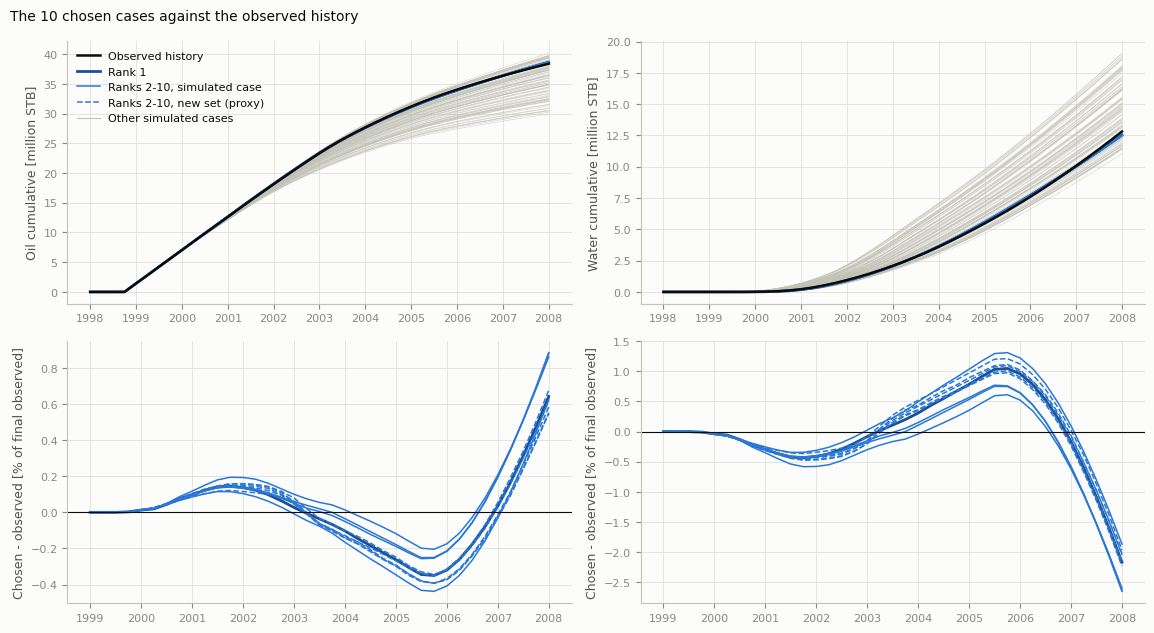

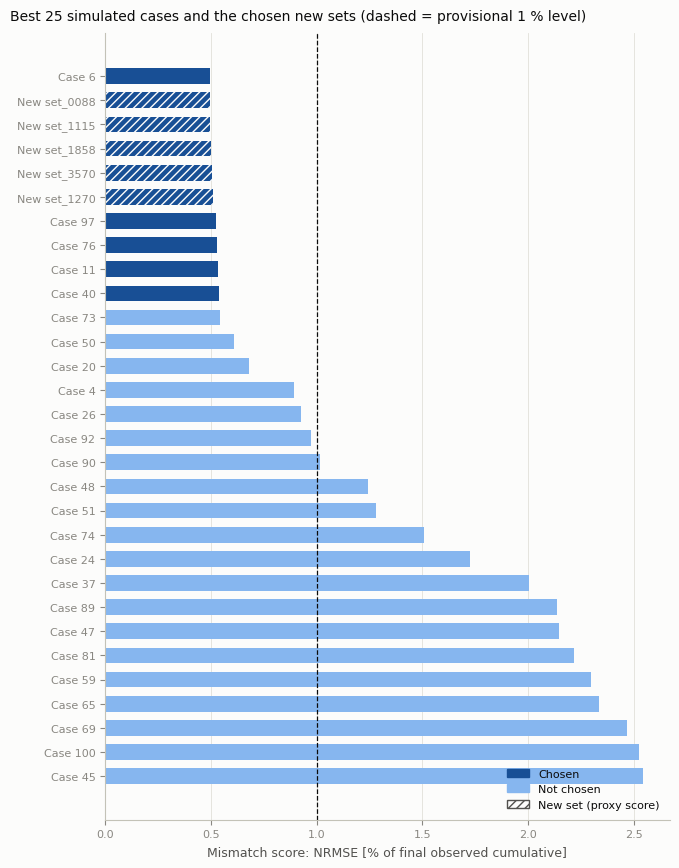

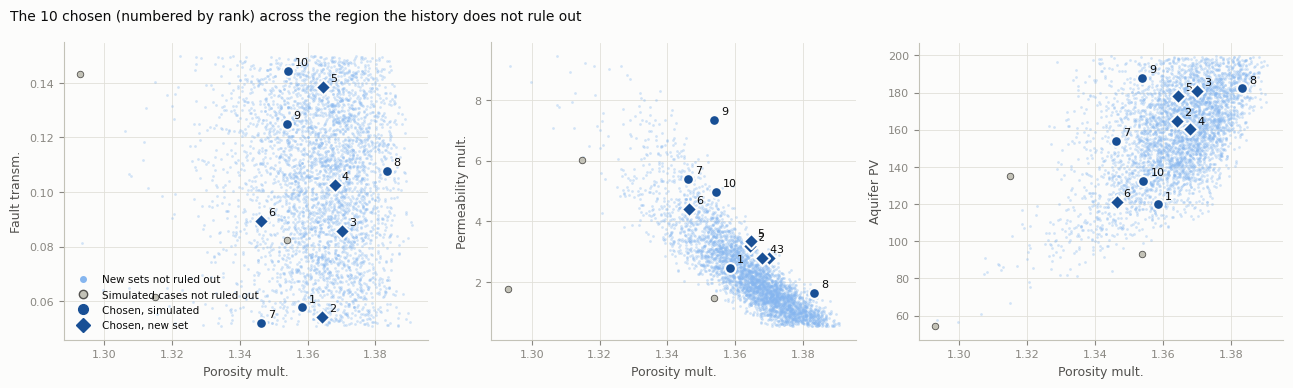

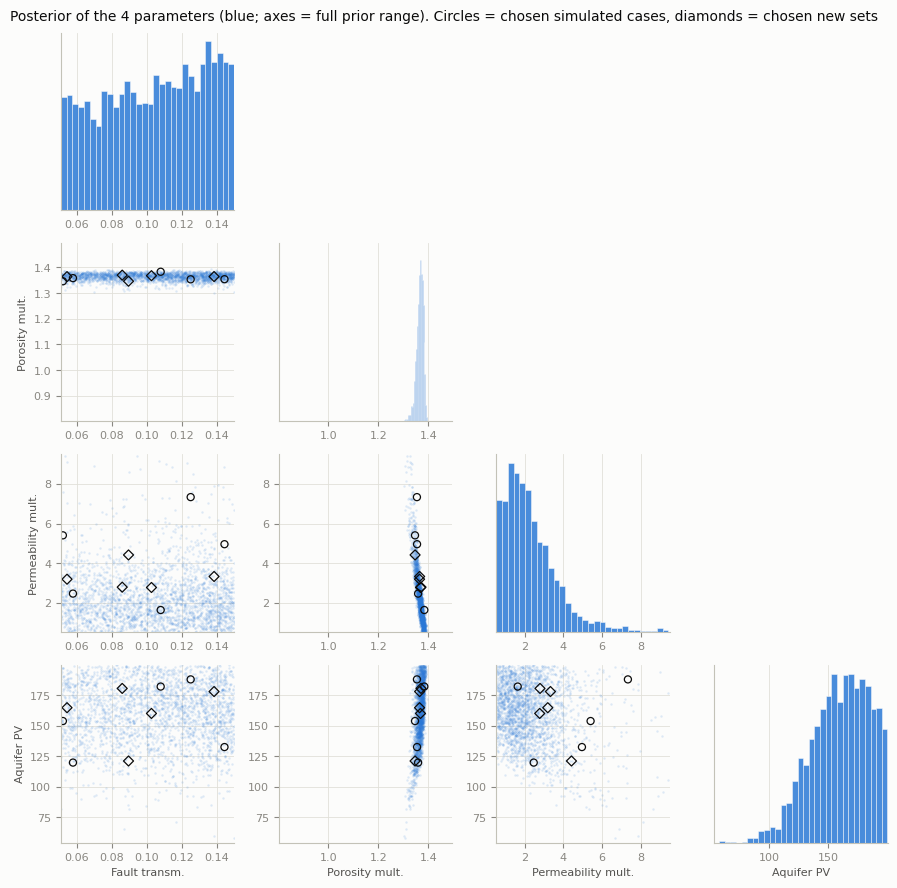

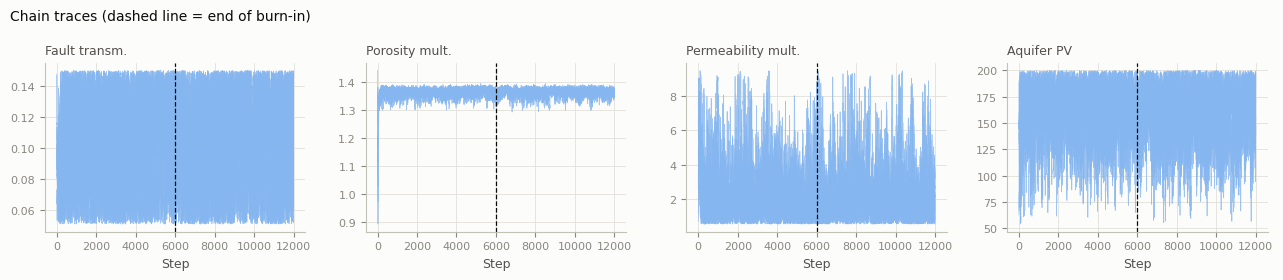

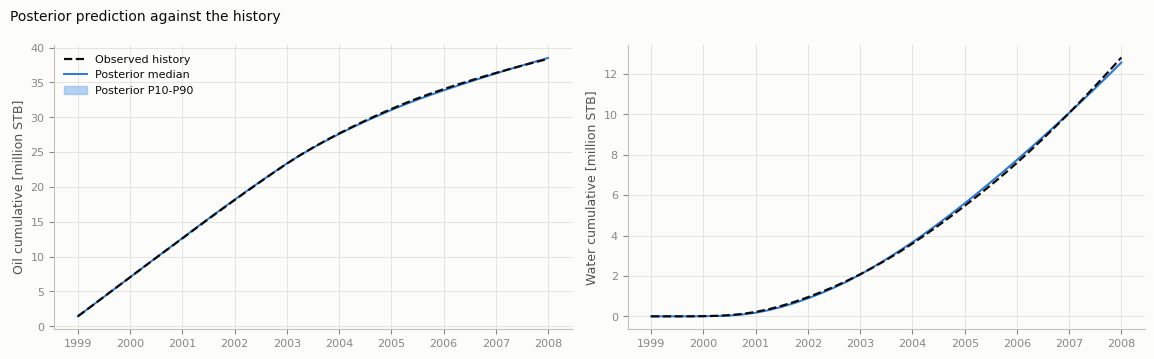

In [13]:
plot_fit(RES, TOP, SERIES, f"fit_top10_{TAG}")
plot_scores(CAND, TOP, CFG, 25, f"scores_{TAG}")
plot_selection(ACC, TOP, f"selection_{TAG}")
plot_posterior(RES, TOP, f"posterior_{TAG}")
plot_trace(RES, f"trace_{TAG}")
plot_predictive(RES, f"predictive_{TAG}")

### Comparison with other ways of choosing the 10

* **Simulated only (v1 method A):** the 10 best simulated cases by score, skipping near-copies (`min_sep`).
* **Elton:** his 10 (`Elton Model/proxy_outputs/hm_top10_parameters.csv`), scored here with the same proxy and score.
* **Zi Yang:** his 10 (printed in `history_matching_ziyang.ipynb`, section 4; copied below), scored the same way.

The proxy only covers the train range. Sets outside it are flagged: their proxy curves are extrapolations.

In [14]:
def describe_choice(name, theta, scores_, imax, src_sim):
    th = np.asarray(theta, float)
    outside = int((((th < BOUNDS["train_min"].to_numpy() - 1e-9) | (th > BOUNDS["train_max"].to_numpy() + 1e-9)).any(1)).sum())
    return {"choice": name, "n_simulated": int(src_sim), "best_score_%": scores_.min() * 100,
            "mean_score_%": scores_.mean() * 100, "worst_score_%": scores_.max() * 100,
            "not_ruled_out": int((imax <= CFG.impl_cut).sum()), "outside_train_range": outside,
            "mean_pairwise_distance": mean_pairwise(th), "poro_range": f"{th[:, 1].min():.3f}-{th[:, 1].max():.3f}"}


rows = [describe_choice("Hybrid (this notebook)", TOP[PARAMS], TOP["score"], TOP["I_max"], (TOP.source == "simulated").sum())]
A_IDS = choose_top_simulated(RES.scores, SIM, CFG.n_top, CFG.min_sep)
sa = RES.scores.loc[A_IDS]
rows.append(describe_choice("Simulated only (v1 method A)", SIM.params.loc[A_IDS, PARAMS], sa["score"], sa["I_max"], 10))
ELTON10 = pd.read_csv(ROOT / "Elton Model" / "proxy_outputs" / "hm_top10_parameters.csv")
ZIYANG10 = pd.DataFrame([   # history_matching_ziyang.ipynb, section 4 output (4 decimals)
    [0.0613, 1.3856, 0.7056, 192.0529], [0.0883, 1.3823, 0.9959, 197.7106], [0.1407, 1.3809, 1.0646, 172.7025],
    [0.1374, 1.3770, 1.1249, 152.6366], [0.0752, 1.3763, 0.7775, 144.7887], [0.1225, 1.3436, 8.9068, 198.3045],
    [0.0728, 1.3433, 9.3346, 192.3107], [0.1395, 1.3509, 3.6258, 121.4743], [0.1116, 1.3520, 4.1597, 133.9612],
    [0.0606, 1.3511, 3.7358, 110.4950]], columns=PARAMS)
OTHER = {}
for nm, df in [("Elton (his 10, our proxy)", ELTON10), ("Zi Yang (his 10, our proxy)", ZIYANG10)]:
    m = curve_metrics(PROXY(df[PARAMS].to_numpy()), RES.win, CFG.impl_sd, PROXY.sigma_proxy)
    OTHER[nm] = df[PARAMS].assign(**{c: m[c].to_numpy() for c in ["score", "nrmse_oil", "nrmse_water", "I_max"]})
    rows.append(describe_choice(nm, df[PARAMS], m["score"], m["I_max"], 0))
COMPARE = pd.DataFrame(rows).set_index("choice")
print(COMPARE.round(4).to_string())
print("\nSimulated-only list (v1 method A):", A_IDS)

                              n_simulated  best_score_%  mean_score_%  worst_score_%  not_ruled_out  outside_train_range  mean_pairwise_distance   poro_range
choice                                                                                                                                                       
Hybrid (this notebook)                  5        0.4939        0.5117         0.5370             10                    0                  0.5711  1.346-1.383
Simulated only (v1 method A)           10        0.4939        0.6264         0.9251              6                    0                  0.7173  1.346-1.383
Elton (his 10, our proxy)               0        0.5113        0.5308         0.5720             10                    9                  0.4268  1.349-1.372
Zi Yang (his 10, our proxy)             0        0.5039        0.5126         0.5199             10                    0                  0.7272  1.343-1.386

Simulated-only list (v1 method A): [6, 97, 76, 11, 

**How to read the comparison.** `mean_pairwise_distance` is the average distance between two of the 10 in the 0-1 scaled parameter space: higher means more different explanations of the field. A choice that only scores well is not enough. The 10 should also be spread over the region the history allows, because they feed a 20-year forecast whose uncertainty the history does not resolve.

## 10. Checks (v2 additions 10b-10g)

### 10b. Direct sampling: a second, independent check of the posterior

Draw the 4 parameters from the prior box and weight each draw by its posterior probability (importance sampling, same likelihood and prior as the MCMC). No chains, so no R-hat; the check is the effective sample size (ESS).

* **Change from v2.** v2 also drew the two noise levels at random. Their posterior is narrow on the log scale, so almost every draw got a weight near zero (ESS below 100 even with 3.2 million draws here). The likelihood is a sum of one term per quantity, each with its own noise level, so the noise levels are integrated out exactly on a 1-D grid instead. The weights are then the marginal posterior of the 4 parameters.
* **Agreement:** ESS of at least 1,000, means within 0.3 posterior sd, and sd within 25 %.

direct sampling: 400,000 draws in 19 s; effective sample size 1,326
             mean_mcmc  mean_direct  shift_in_sd  sd_mcmc  sd_direct  sd_ratio
parameter                                                                     
fault_trans     0.1037       0.1030      -0.0232   0.0283     0.0281    0.9933
poro_mult       1.3647       1.3649       0.0146   0.0128     0.0128    0.9965
perm_mult       2.2743       2.2653      -0.0067   1.3550     1.3382    0.9876
aquifer_pv    159.7647     160.5656       0.0329  24.3608    24.1736    0.9923

Verdict: AGREE. The MCMC result is confirmed by a method with no chains.


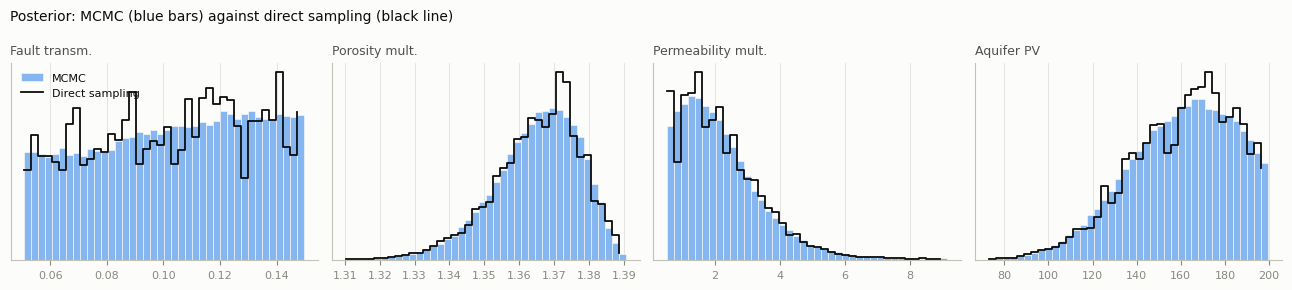

In [15]:
def weighted_quantile(x, w, qs):
    o = np.argsort(x)
    cw = np.cumsum(w[o]); cw = cw / cw[-1]
    return np.interp(qs, cw, x[o])


def weighted_stats(x, w):
    m = float(np.sum(w * x))
    return (m, float(np.sqrt(np.sum(w * (x - m) ** 2))), *weighted_quantile(x, w, [0.05, 0.5, 0.95]))


def direct_sampling(res, n=400_000, batch=20_000, seed=1, n_grid=400):
    # Importance sampling of the 4 parameters from the uniform prior box. The two noise levels are
    # integrated out exactly on a 1-D grid each (the likelihood is a sum over quantities, and each
    # term depends on its own noise level only), so the weights are the marginal posterior of theta.
    # Drawing the noise levels at random instead wastes almost every draw (their posterior is narrow).
    lp = LogPosterior(res.proxy, res.win, res.rho, res.cfg, BOUNDS)
    a, b = res.cfg.log_sigma_range
    ls = np.linspace(a, b, n_grid)
    s2 = np.exp(2 * ls)[None, :, None] + lp.sigma_proxy[None, None, :] ** 2         # (1, G, Q)
    c, T = 1.0 - res.rho ** 2, len(res.win.dates)
    X = lp.lo + np.random.default_rng(seed).random((n, 4)) * (lp.hi - lp.lo)
    out = []
    for i in range(0, n, batch):
        R = (res.win.Yh[None] - res.proxy(X[i:i + batch])) / res.win.scale
        rss = (whiten(R, res.rho) ** 2).sum(axis=1)                                   # (m, Q)
        ll = -0.5 * T * np.log(s2) - 0.5 * (T - 1) * np.log(c) - rss[:, None, :] / (2 * s2 * c)   # (m, G, Q)
        mx = ll.max(axis=1, keepdims=True)
        out.append((np.log(np.exp(ll - mx).mean(axis=1)) + mx[:, 0, :]).sum(axis=1))  # uniform prior on log sigma
    logp = np.concatenate(out) + lp.log_prior(np.c_[X, np.full((n, lp.Q), 0.5 * (a + b))])
    w = np.exp(logp - logp.max()); w = w / w.sum()
    return X, w, float(1.0 / np.sum(w ** 2))


def compare_posteriors(res, X, w):
    s = res.posterior["summary"]
    rows = []
    for j, nm in enumerate(PARAMS):
        m, sd, p05, p50, p95 = weighted_stats(X[:, j], w)
        mc = s.loc[nm]
        rows.append(dict(parameter=nm, mean_mcmc=mc["mean"], mean_direct=m, shift_in_sd=(m - mc["mean"]) / mc["sd"],
                         sd_mcmc=mc["sd"], sd_direct=sd, sd_ratio=sd / mc["sd"],
                         p05_mcmc=mc["p05"], p05_direct=p05, p95_mcmc=mc["p95"], p95_direct=p95))
    return pd.DataFrame(rows).set_index("parameter")


t0 = time.time()
DS_X, DS_W, DS_ESS = direct_sampling(RES)
n_ds = 400_000
while DS_ESS < 1000 and n_ds < 1_600_000:          # porosity is narrow: add draws until the ESS is large enough
    n_ds *= 2
    DS_X, DS_W, DS_ESS = direct_sampling(RES, n=n_ds)
DS_CMP = compare_posteriors(RES, DS_X, DS_W)
print(f"direct sampling: {len(DS_X):,} draws in {time.time() - t0:.0f} s; effective sample size {DS_ESS:,.0f}")
print(DS_CMP[["mean_mcmc", "mean_direct", "shift_in_sd", "sd_mcmc", "sd_direct", "sd_ratio"]].round(4).to_string())
DS_ENOUGH = DS_ESS >= 1000
DS_AGREE = bool(DS_ENOUGH and (DS_CMP["shift_in_sd"].abs() < 0.3).all() and DS_CMP["sd_ratio"].between(0.75, 1.25).all())
print("\nVerdict:", "AGREE. The MCMC result is confirmed by a method with no chains." if DS_AGREE
      else ("INCONCLUSIVE: effective sample size below 1,000." if not DS_ENOUGH
            else "CHECK. The two methods differ (see the table)."))
DS_CMP.to_csv(HM_DIR / f"direct_vs_mcmc_{TAG}.csv")

fig, axes = plt.subplots(1, 4, figsize=(13, 2.9))
flat = RES.posterior["flat"]
for j in range(4):
    ax = _ax(axes[j])
    bins = np.linspace(np.percentile(flat[:, j], 0.1), np.percentile(flat[:, j], 99.9), 41)
    ax.hist(flat[:, j], bins=bins, density=True, color=BLUE_250, edgecolor=SURF, lw=0.4, label="MCMC")
    h, e = np.histogram(DS_X[:, j], bins=bins, weights=DS_W, density=True)
    ax.step(e[:-1], h, where="post", color=INK, lw=1.3, label="Direct sampling")
    ax.set_title(LAB[j], fontsize=9, loc="left", color=INK2); ax.set_yticks([])
axes[0].legend(frameon=False, fontsize=8)
_finish(fig, f"direct_sampling_{TAG}", "Posterior: MCMC (blue bars) against direct sampling (black line)")

### 10c. Implausibility: which parameter values does the history rule out?

`I = |observed - predicted| / sqrt(impl_sd^2 + proxy error^2)`, worst over oil, water and 4 dates. `I > 3` = ruled out. The rest is the *NROY* (not ruled out yet) space. `impl_sd` (1 %) is the assumed observation + simulator error: **provisional**, so the sensitivity is shown.

200,000 random sets in 6 s: 6.98% of the train-range box is not ruled out.
             prior_min  prior_max  nroy_min  nroy_max  share_of_range_left
fault_trans     0.0508     0.1500    0.0508    0.1500               0.9999
poro_mult       0.8012     1.4940    1.2702    1.3987               0.1856
perm_mult       0.5375     9.5020    0.5389    9.5016               0.9998
aquifer_pv     53.9529   199.8352   53.9917  199.8310               0.9997

Sensitivity to the assumed error:
impl_sd space_not_ruled_out simulated_cases_not_ruled_out
   0.5%               0.18%                      0 of 100
   1.0%               6.98%                      8 of 100
   2.0%              20.89%                     21 of 100


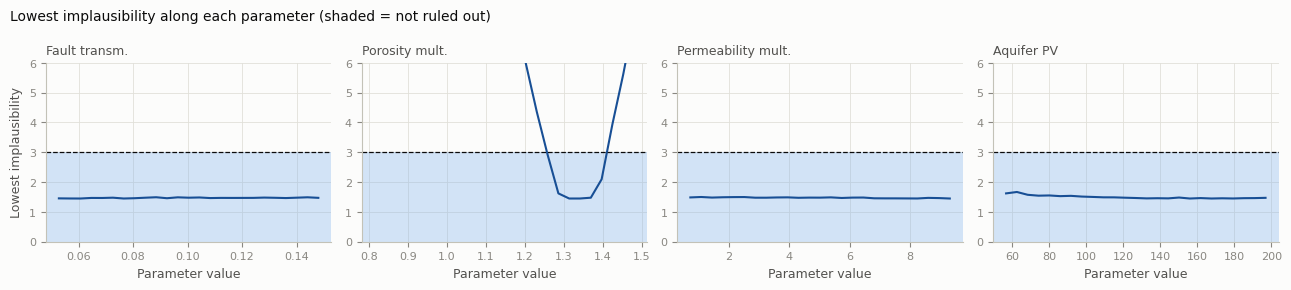

In [16]:
def implausibility_space(res, n=200_000, batch=20_000, seed=2):
    win = res.win
    idx = _impl_idx(len(win.dates))
    lo, hi = BOUNDS["train_min"].to_numpy(), BOUNDS["train_max"].to_numpy()
    theta = lo + np.random.default_rng(seed).random((n, 4)) * (hi - lo)
    absR = np.empty((n, len(win.quantities)))
    for i in range(0, n, batch):
        absR[i:i + batch] = np.abs((res.proxy(theta[i:i + batch])[:, idx, :] - win.Yh[None, idx, :]) / win.scale).max(axis=1)
    return theta, absR


def impl_from_absR(absR, sigma_proxy, sd):
    return (absR / np.sqrt(sd ** 2 + np.asarray(sigma_proxy) ** 2)).max(axis=1)


t0 = time.time()
IM_THETA, IM_ABSR = implausibility_space(RES)
IM_I = impl_from_absR(IM_ABSR, PROXY.sigma_proxy, CFG.impl_sd)
ok = IM_I <= CFG.impl_cut
NROY = pd.DataFrame({"prior_min": BOUNDS["train_min"], "prior_max": BOUNDS["train_max"],
                     "nroy_min": [IM_THETA[ok, j].min() for j in range(4)],
                     "nroy_max": [IM_THETA[ok, j].max() for j in range(4)]}, index=PARAMS)
NROY["share_of_range_left"] = (NROY["nroy_max"] - NROY["nroy_min"]) / (NROY["prior_max"] - NROY["prior_min"])
NROY.to_csv(HM_DIR / f"implausibility_nroy_{TAG}.csv")
print(f"{len(IM_THETA):,} random sets in {time.time() - t0:.0f} s: {ok.mean():.2%} of the train-range box is not ruled out.")
print(NROY.round(4).to_string())
sens = []
for sd_ in (0.005, 0.01, 0.02):
    Ic = curve_metrics(RES.win.Yc, RES.win, sd_)["I_max"]
    sens.append({"impl_sd": f"{sd_:.1%}", "space_not_ruled_out": f"{(impl_from_absR(IM_ABSR, PROXY.sigma_proxy, sd_) <= CFG.impl_cut).mean():.2%}",
                 "simulated_cases_not_ruled_out": f"{int((Ic <= CFG.impl_cut).sum())} of {len(Ic)}"})
IMPL_SENS = pd.DataFrame(sens)
print("\nSensitivity to the assumed error:")
print(IMPL_SENS.to_string(index=False))

fig, axes = plt.subplots(1, 4, figsize=(13, 2.9))
for j in range(4):
    ax = _ax(axes[j])
    edges = np.linspace(IM_THETA[:, j].min(), IM_THETA[:, j].max(), 26)
    b = np.clip(np.digitize(IM_THETA[:, j], edges) - 1, 0, 24)
    prof = np.array([IM_I[b == k].min() if (b == k).any() else np.nan for k in range(25)])
    ax.axhspan(0, CFG.impl_cut, color=BLUE_250, alpha=0.35, lw=0)
    ax.plot(0.5 * (edges[:-1] + edges[1:]), prof, color=BLUE_600, lw=1.5)
    ax.axhline(CFG.impl_cut, color=INK, lw=0.9, ls="--")
    ax.set_ylim(0, 2 * CFG.impl_cut)
    ax.set_title(LAB[j], fontsize=9, loc="left", color=INK2); ax.set_xlabel("Parameter value")
axes[0].set_ylabel("Lowest implausibility")
_finish(fig, f"implausibility_{TAG}", "Lowest implausibility along each parameter (shaded = not ruled out)")

### 10d. Global search: what is the best score the proxy can reach?

Differential evolution on the proxy score, 10 runs from different seeds, inside the train range. It shows the best achievable match and whether it sits on the edge of the range (where the proxy has the fewest training cases).

In [17]:
def proxy_score(theta):
    return curve_metrics(PROXY(theta), RES.win)["score"].to_numpy()


t0 = time.time()
lo_b, hi_b = BOUNDS["train_min"].to_numpy(), BOUNDS["train_max"].to_numpy()
rs = np.random.default_rng(3)
de_rows = []
for k in range(10):
    r = differential_evolution(lambda Z: proxy_score(lo_b + Z.T * (hi_b - lo_b)), [(0, 1)] * 4, vectorized=True,
                               updating="deferred", popsize=15, maxiter=150, tol=1e-10, polish=False,
                               seed=int(rs.integers(2 ** 31 - 1)))
    de_rows.append({"run": k, **dict(zip(PARAMS, lo_b + r.x * (hi_b - lo_b))), "proxy_score": float(r.fun),
                    "at_edge": ",".join(nm for nm, v in zip(PARAMS, r.x) if v < 0.02 or v > 0.98)})
SEARCH = pd.DataFrame(de_rows).sort_values("proxy_score")
SEARCH.to_csv(HM_DIR / f"global_search_{TAG}.csv", index=False)
best_sim = RES.scores["score"].min()
print(f"{time.time() - t0:.0f} s. Best proxy score {SEARCH.proxy_score.min():.4%} (best simulated case {best_sim:.4%}; "
      f"proxy error {EPS:.4%}). Spread of the 10 runs (0-1 scaled): "
      f"{dict(zip(PARAMS, np.round(scaled(SEARCH[PARAMS].to_numpy()).std(0), 3)))}")
print(SEARCH.round(4).to_string(index=False))

5 s. Best proxy score 0.4842% (best simulated case 0.4939%; proxy error 0.1108%). Spread of the 10 runs (0-1 scaled): {'fault_trans': np.float64(0.0), 'poro_mult': np.float64(0.0), 'perm_mult': np.float64(0.0), 'aquifer_pv': np.float64(0.0)}
 run  fault_trans  poro_mult  perm_mult  aquifer_pv  proxy_score               at_edge
   5       0.0508     1.3345     9.5020    151.8160       0.0048 fault_trans,perm_mult
   0       0.0508     1.3345     9.5019    151.8390       0.0048 fault_trans,perm_mult
   3       0.0508     1.3345     9.5019    151.8005       0.0048 fault_trans,perm_mult
   4       0.0508     1.3345     9.5019    151.8938       0.0048 fault_trans,perm_mult
   8       0.0508     1.3345     9.5019    151.8981       0.0048 fault_trans,perm_mult
   6       0.0508     1.3345     9.5019    151.8274       0.0048 fault_trans,perm_mult
   7       0.0508     1.3345     9.5019    151.7812       0.0048 fault_trans,perm_mult
   2       0.0508     1.3345     9.5019    151.9492       0.00

### 10e. Oil and water trade-off (simulated cases)

Left: oil NRMSE against water NRMSE; the front (Pareto) holds the cases that no other case beats in both. Right: the signed error on the last date shows the direction of the bias.

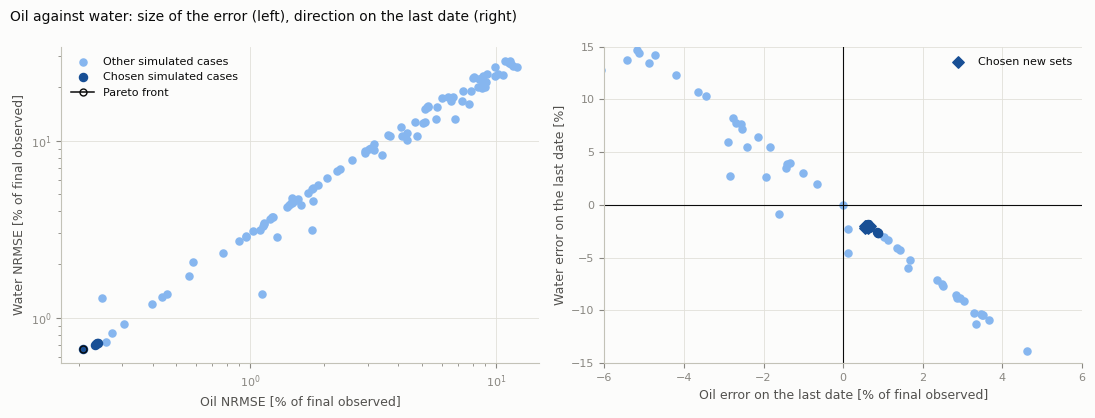

Simulated cases on the oil-water Pareto front: [6]


In [18]:
def pareto_mask(x, y):
    return np.array([not np.any((x <= x[i]) & (y <= y[i]) & ((x < x[i]) | (y < y[i]))) for i in range(len(x))])


sc = RES.scores
chosen_sim = set(TOP["case_id"].dropna().astype(int))
ch = sc.index.isin(chosen_sim)
ox, wy = sc["nrmse_oil"].to_numpy() * 100, sc["nrmse_water"].to_numpy() * 100
par = pareto_mask(ox, wy)
PARETO_IDS = list(sc.index[par])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = _ax(axes[0])
ax.scatter(ox[~ch], wy[~ch], s=26, color=BLUE_250, label="Other simulated cases")
ax.scatter(ox[ch], wy[ch], s=34, color=BLUE_600, label="Chosen simulated cases")
o = np.argsort(ox[par])
ax.plot(ox[par][o], wy[par][o], color=INK, lw=1.1, marker="o", ms=5, mfc="none", label="Pareto front")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Oil NRMSE [% of final observed]"); ax.set_ylabel("Water NRMSE [% of final observed]")
ax.legend(frameon=False, fontsize=8, loc="upper left")
ax = _ax(axes[1])
fo, fw = sc["err_final_oil"].to_numpy() * 100, sc["err_final_water"].to_numpy() * 100
ax.axhline(0, color=INK, lw=0.8); ax.axvline(0, color=INK, lw=0.8)
ax.scatter(fo[~ch], fw[~ch], s=26, color=BLUE_250)
ax.scatter(fo[ch], fw[ch], s=34, color=BLUE_600)
nw = TOP[TOP.source == "new_set"]
ax.scatter(nw["err_final_oil"] * 100, nw["err_final_water"] * 100, s=34, marker="D", color=BLUE_600, label="Chosen new sets")
ax.set_xlim(-6, 6); ax.set_ylim(-15, 15)
ax.set_xlabel("Oil error on the last date [% of final observed]"); ax.set_ylabel("Water error on the last date [%]")
ax.legend(frameon=False, fontsize=8, loc="upper right")
_finish(fig, f"tradeoff_{TAG}", "Oil against water: size of the error (left), direction on the last date (right)")
print("Simulated cases on the oil-water Pareto front:", PARETO_IDS)

### 10f. Hold-out check: does a good fit to early history predict later history?

Score the simulated cases on the first 70 % of the window only, choose the top 10 on that, and test them on the last 30 %. Compare with the median case and with the oracle (best 10 on the late part).

early_end_date                 2005-04-01
late_mean_chosen_on_early_%         1.072
late_mean_pool_median_%            10.174
late_mean_oracle_%                  1.052
overlap_with_oracle                     9
spearman_early_vs_late              0.993

Chosen on the early period: [50, 20, 11, 40, 26, 76, 6, 4, 73, 97] 
Oracle (best on the late period): [6, 97, 73, 76, 11, 40, 50, 20, 90, 4]


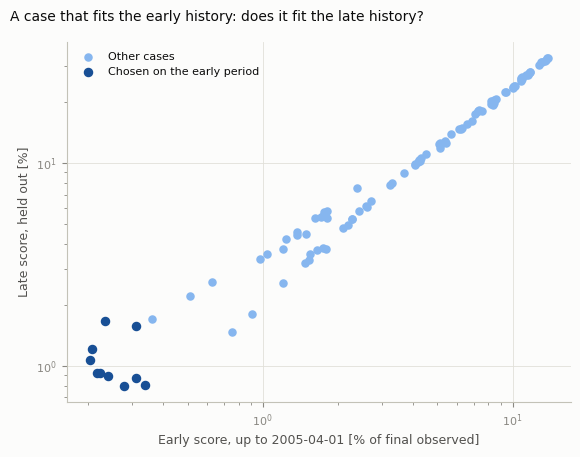

In [19]:
def holdout_check(res, frac=0.7, n_top=10):
    win = res.win
    R = (win.Yc - win.Yh[None]) / win.scale
    k = int(round(frac * R.shape[1]))
    part = lambda a: np.sqrt((a ** 2).mean(axis=1).mean(axis=1))
    df = pd.DataFrame({"early": part(R[:, :k]), "late": part(R[:, k:])}, index=pd.Index(win.case_ids, name="case_id"))
    df["rank_early"] = df["early"].rank(method="first").astype(int)
    df["rank_late"] = df["late"].rank(method="first").astype(int)
    ids = choose_top_simulated(df.rename(columns={"early": "score"}), res.cs, n_top, res.cfg.min_sep)
    orc = choose_top_simulated(df.rename(columns={"late": "score"}), res.cs, n_top, res.cfg.min_sep)
    summ = pd.Series({
        "early_end_date": str(win.dates[k - 1]),
        "late_mean_chosen_on_early_%": df.loc[ids, "late"].mean() * 100,
        "late_mean_pool_median_%": df["late"].median() * 100,
        "late_mean_oracle_%": df.loc[orc, "late"].mean() * 100,
        "overlap_with_oracle": len(set(ids) & set(orc)),
        "spearman_early_vs_late": df[["early", "late"]].corr(method="spearman").iloc[0, 1],
    })
    return df, summ, ids, orc


HOLD, HOLD_SUMM, HOLD_IDS, HOLD_ORACLE = holdout_check(RES)
print(HOLD_SUMM.to_string(float_format=lambda v: f"{v:.3f}"))
print("\nChosen on the early period:", HOLD_IDS, "\nOracle (best on the late period):", HOLD_ORACLE)
HOLD.assign(chosen_on_early=HOLD.index.isin(HOLD_IDS)).to_csv(HM_DIR / f"holdout_{TAG}.csv")
fig, ax = plt.subplots(figsize=(5.8, 4.6))
_ax(ax)
c_ = HOLD.index.isin(HOLD_IDS)
ax.scatter(HOLD.loc[~c_, "early"] * 100, HOLD.loc[~c_, "late"] * 100, s=26, color=BLUE_250, label="Other cases")
ax.scatter(HOLD.loc[c_, "early"] * 100, HOLD.loc[c_, "late"] * 100, s=34, color=BLUE_600, label="Chosen on the early period")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(f"Early score, up to {HOLD_SUMM['early_end_date']} [% of final observed]")
ax.set_ylabel("Late score, held out [%]")
ax.legend(frameon=False, fontsize=8, loc="upper left")
_finish(fig, f"holdout_{TAG}", "A case that fits the early history: does it fit the late history?")

### 10g. Scorecard (simulated cases)

| Layer | Question | Columns |
|---|---|---|
| 1. Fit | How far is the curve from the history? | `score_%`, `max_err_%`, `err_final_oil_%`, `err_final_water_%` |
| 2. Case against case | Which case is closer? | `rank_A`, `vs_best`, `post_dist` |
| 3. Against a benchmark | Is it good enough? | `I_max`, `not_ruled_out` |
| 4. Beyond the fit | Does it hold on history it did not use? | `early_%`, `late_%`, `pareto` |

In [20]:
card = pd.DataFrame(index=sc.index)
card["split"] = SPLIT.loc[sc.index]
card["score_%"] = sc["score"] * 100
card["vs_best"] = sc["score"] / sc["score"].min()
card["max_err_%"] = sc["max_rel_err"] * 100
card["err_final_oil_%"] = sc["err_final_oil"] * 100
card["err_final_water_%"] = sc["err_final_water"] * 100
card["rank_A"] = sc["rank_A"]
card["post_dist"] = sc["post_dist"]
card["I_max"] = sc["I_max"]
card["not_ruled_out"] = card["I_max"] <= CFG.impl_cut
card["early_%"] = HOLD["early"] * 100
card["late_%"] = HOLD["late"] * 100
card["pareto"] = card.index.isin(PARETO_IDS)
card["chosen"] = card.index.isin(chosen_sim)
SCORECARD = card.sort_values("rank_A")
SCORECARD.to_csv(HM_DIR / f"scorecard_{TAG}.csv")
SCORECARD.head(15).round(3)

,split,score_%,vs_best,max_err_%,err_final_oil_%,err_final_water_%,rank_A,post_dist,I_max,not_ruled_out,early_%,late_%,pareto,chosen
case_id,,,,,,,,,,,,,,
6,train,0.494,1.000,2.164,0.641,-2.164,1,2.502,2.164,True,0.279,0.798,True,True
97,test,0.522,1.057,1.865,0.623,-1.865,2,3.387,1.865,True,0.338,0.804,False,True
76,validation,0.528,1.069,2.598,0.860,-2.598,3,2.740,2.598,True,0.240,0.895,False,True
11,train,0.533,1.078,2.635,0.880,-2.635,4,7.397,2.635,True,0.218,0.918,False,True
40,train,0.537,1.087,2.648,0.884,-2.648,5,5.160,2.648,True,0.222,0.924,False,True
73,validation,0.544,1.100,2.317,0.116,-2.317,6,3.173,2.317,True,0.311,0.875,False,False
50,train,0.609,1.234,3.056,1.020,-3.056,7,9.031,3.056,False,0.202,1.073,False,False
20,train,0.682,1.380,3.361,1.122,-3.361,8,7.529,3.361,False,0.208,1.208,False,False
4,train,0.892,1.805,4.058,1.355,-4.058,9,14.343,4.058,False,0.310,1.564,False,False


## 11. Recovery test: does the pipeline find the right answer when the answer is known?

Use a **validation case** as a fake history (with noise). Remove it from the pool of simulated cases, run the whole pipeline, and check:

* are the true parameters inside the posterior 5-95 % interval (`cover_4` = how many of the 4)?
* how far is the posterior-mean porosity from the truth (`poro_err_%`, `z_poro` in posterior sd)?
* do the 10 chosen fit the **noise-free** fake history about as well as the best 10 simulated cases of the pool (`mean10_chosen_%` against `mean10_oracle_%`)?

5 validation cases x 2 noise levels (0.5 % and 2 % of the final value, independent Gaussian, a stress test). Lighter MCMC (2 ensembles x 10,000 steps; 6,000 left one run of ten at R-hat 1.11).

**Caution on `mean10_chosen_%`.** For a chosen new set the curve is the proxy's, so its score against the fake history leaves out the proxy error (about 0.15 % in score units). Because the fake history is itself a simulated case, the proxy reproduces it closely, and this number is optimistic. The parameter-recovery columns (`cover_4`, `poro_err_%`, `z_poro`) do not have this issue.

In [21]:
CFG_T = replace(CFG, n_ensembles=2, n_steps=10000, n_post_candidates=2000)


def add_noise(y, rel_sd, rng_):
    if rel_sd == 0:
        return y.copy()
    return np.where(y > 0, np.maximum(y + rng_.normal(0, rel_sd * y[-1], len(y)), 0), 0.0)


def recovery_run(true_id, noise, seed):
    i = int(np.where(SIM.case_ids == true_id)[0][0])
    clean = History(SIM.dates, {q: SIM.curves[q][i].copy() for q in ALL_Q})
    r_ = np.random.default_rng(seed)
    noisy = History(SIM.dates, {q: (v if q == "gas_cum" else add_noise(v, noise, r_)) for q, v in clean.curves.items()})
    pool = subset(SIM, SIM.case_ids[SIM.case_ids != true_id])
    th_true = SIM.params.loc[true_id, PARAMS].to_numpy(float)
    res_t = run_history_matching(pool, noisy, CFG_T, PROXY, true_theta=th_true, verbose=False)
    cand_t = build_candidates(res_t, CFG_T, seed=seed)
    top_t, _, note_t = hybrid_select(cand_t, CFG_T, EPS, seed=seed)
    win_c = align_window(pool, clean, CFG.match_quantities)           # the same pool against the clean fake history
    sim_clean = curve_metrics(win_c.Yc, win_c)["score"].to_numpy()
    th_top = top_t[PARAMS].to_numpy(float)
    curves = np.empty((len(top_t), len(win_c.dates), len(CFG.match_quantities)))
    for k, (cid, r) in enumerate(top_t.iterrows()):
        if r["source"] == "simulated":
            curves[k] = win_c.Yc[int(np.where(win_c.case_ids == int(r["case_id"]))[0][0])]
        else:
            curves[k] = res_t.proxy(th_top[k][None])[0]
    s = res_t.posterior["summary"]
    cover = [bool(s.loc[nm, "p05"] <= th_true[k] <= s.loc[nm, "p95"]) for k, nm in enumerate(PARAMS)]
    return {"true_id": true_id, "noise_%": noise * 100, "rho": res_t.rho,
            "cover_4": int(sum(cover)), **{f"cover_{nm}": c for nm, c in zip(PARAMS, cover)},
            "poro_err_%": (res_t.posterior["mean"][1] - th_true[1]) / th_true[1] * 100,
            "z_poro": (res_t.posterior["mean"][1] - th_true[1]) / s.loc["poro_mult", "sd"],
            "max_rhat": float(res_t.posterior["diag"]["r_hat"].max()),
            "mean10_chosen_%": curve_metrics(curves, win_c)["score"].mean() * 100,
            "mean10_oracle_%": np.sort(sim_clean)[:10].mean() * 100,
            "best_pool_%": sim_clean.min() * 100,
            "n_new_sets_chosen": int((top_t["source"] == "new_set").sum()), "note": note_t}


t0 = time.time()
VAL_IDS = np.sort(np.random.default_rng(7).choice(SPLIT.index[SPLIT == "validation"].to_numpy(), 5, replace=False))
REC = pd.DataFrame([recovery_run(int(tid), nz, 100 + k) for nz in (0.005, 0.02) for k, tid in enumerate(VAL_IDS)])
REC.to_csv(HM_DIR / f"recovery_test_{TAG}.csv", index=False)
print(f"{len(REC)} recovery runs in {time.time() - t0:.0f} s; fake histories from validation cases {VAL_IDS.tolist()}")
print(REC.drop(columns=[c for c in REC.columns if c.startswith("cover_") and c != "cover_4"] + ["note"]).round(3).to_string(index=False))
print("\nTrue value inside the posterior 5-95 % interval, share of runs per parameter:")
print(REC[[f"cover_{nm}" for nm in PARAMS]].mean().round(2).to_string())

10 recovery runs in 294 s; fake histories from validation cases [78, 79, 81, 83, 85]
 true_id  noise_%   rho  cover_4  poro_err_%  z_poro  max_rhat  mean10_chosen_%  mean10_oracle_%  best_pool_%  n_new_sets_chosen
      78      0.5 0.499        4       0.982   0.803     1.043            0.113            0.756        0.139                  8
      79      0.5 0.539        4      -0.245  -0.217     1.048            0.094            0.727        0.182                  8
      81      0.5 0.363        4       0.749   0.508     1.080            0.132            0.685        0.278                  8
      83      0.5 0.682        4      -0.118  -0.067     1.034            0.097            1.129        0.499                 10
      85      0.5 0.843        4       0.048   0.032     1.037            0.135            1.452        1.262                 10
      78      2.0 0.052        4       1.327   0.820     1.035            0.319            0.756        0.139                  9
      79    

In [22]:
checks = {
    "MCMC converged on the real history (max R-hat < 1.1)": bool(RES.posterior["diag"]["r_hat"].max() < 1.1),
    "Direct sampling agrees with the MCMC": DS_AGREE,
    "Recovery: porosity recovered within 2 % on average": bool(REC["poro_err_%"].abs().mean() < 2),
    "Recovery: true values inside the 5-95 % interval in >= 80 % of parameter-runs": bool(REC["cover_4"].sum() / (4 * len(REC)) >= 0.8),
    "Recovery: chosen 10 fit the clean fake history within 1.5x the pool's best 10": bool((REC["mean10_chosen_%"] <= 1.5 * REC["mean10_oracle_%"]).all()),
    "Recovery runs converged (max R-hat < 1.1 in every run)": bool((REC["max_rhat"] < 1.1).all()),
    "All 10 chosen are not ruled out (I_max <= 3)": bool((TOP["I_max"] <= CFG.impl_cut).all()),
    "All 10 chosen inside the train range": bool(COMPARE.loc["Hybrid (this notebook)", "outside_train_range"] == 0),
}
CHECKS = pd.Series(checks)
for k, v in checks.items():
    print("PASS" if v else "FAIL", "-", k)

PASS - MCMC converged on the real history (max R-hat < 1.1)
PASS - Direct sampling agrees with the MCMC
PASS - Recovery: porosity recovered within 2 % on average
PASS - Recovery: true values inside the 5-95 % interval in >= 80 % of parameter-runs
PASS - Recovery: chosen 10 fit the clean fake history within 1.5x the pool's best 10
PASS - Recovery runs converged (max R-hat < 1.1 in every run)
PASS - All 10 chosen are not ruled out (I_max <= 3)
PASS - All 10 chosen inside the train range


## 12. Export

In [23]:
def export_results():
    TOP.to_csv(HM_DIR / f"top10_cases_{TAG}.csv")
    SERIES.to_csv(HM_DIR / f"top10_series_{TAG}.csv", index=False)
    RES.scores.join(SPLIT).join(SIM.params).to_csv(HM_DIR / f"scores_all_{TAG}.csv")
    CAND.join(ACC[["cluster"]]).to_csv(HM_DIR / f"candidates_{TAG}.csv")
    RES.posterior["summary"].to_csv(HM_DIR / f"posterior_summary_{TAG}.csv")
    RES.posterior["diag"].to_csv(HM_DIR / f"mcmc_diagnostics_{TAG}.csv")
    cols = PARAMS + [f"log_sigma_{q.replace('_cum', '')}" for q in RES.win.quantities]
    pd.DataFrame(RES.posterior["flat"][::10], columns=cols).to_csv(HM_DIR / f"posterior_samples_{TAG}.csv", index=False)
    COMPARE.to_csv(HM_DIR / f"selection_comparison_{TAG}.csv")
    pd.concat({k: v for k, v in OTHER.items()}, names=["choice", "row"]).to_csv(HM_DIR / f"other_teams_10_scored_{TAG}.csv")
    IMPL_SENS.to_csv(HM_DIR / f"implausibility_sensitivity_{TAG}.csv", index=False)
    summary = {
        "proxy": {"sha256": META["model_sha256"], "config": META["config"], "sigma_proxy": META["sigma_proxy"]},
        "window": [str(RES.win.dates[0]), str(RES.win.dates[-1]), int(len(RES.win.dates))],
        "rho": RES.rho,
        "best_simulated": {"case_id": int(RES.scores["score"].idxmin()), "score": float(RES.scores["score"].min())},
        "median_simulated_score": float(RES.scores["score"].median()),
        "simulated_not_ruled_out": int((RES.scores["I_max"] <= CFG.impl_cut).sum()),
        "mcmc": {"acceptance": float(np.mean(RES.posterior["acc"])), "max_rhat": float(RES.posterior["diag"]["r_hat"].max()),
                 "max_tau": float(RES.posterior["diag"]["autocorr_time"].max()), "ess": float(RES.posterior["ess"]),
                 "posterior_mean_score": RES.posterior["nrmse_mean"], "map_score": RES.posterior["nrmse_map"]},
        "direct_sampling": {"ess": DS_ESS, "agree": DS_AGREE},
        "nroy_share": float((IM_I <= CFG.impl_cut).mean()),
        "global_search_best_score": float(SEARCH.proxy_score.min()),
        "eps": EPS,
        "top10": TOP[["rank", "source", "case_id", "score", "I_max"] + PARAMS].reset_index().to_dict(orient="records"),
        "selection_note": SEL_NOTE,
        "checks": {k: bool(v) for k, v in checks.items()},
        "holdout": {k: (float(v) if not isinstance(v, str) else v) for k, v in HOLD_SUMM.items()},
    }
    (HM_DIR / f"hm_run_summary_{TAG}.json").write_text(json.dumps(summary, indent=2, default=float))
    print("saved to", HM_DIR)
    for f in sorted(HM_DIR.glob("*.*")):
        print(f"  {f.name:<38} {f.stat().st_size / 1e3:>9.1f} kB")


export_results()

saved to C:\Users\Yi Siang\Documents\UM\dwc_team_what_repo\hist_match_output
  candidates_real.csv                       1109.3 kB
  direct_vs_mcmc_real.csv                      0.9 kB
  global_search_real.csv                       1.3 kB
  hm_run_summary_real.json                     5.7 kB
  holdout_real.csv                             5.7 kB
  implausibility_nroy_real.csv                 0.5 kB
  implausibility_sensitivity_real.csv          0.1 kB
  mcmc_diagnostics_real.csv                    0.3 kB
  other_teams_10_scored_real.csv               3.4 kB
  posterior_samples_real.csv                4411.7 kB
  posterior_summary_real.csv                   0.8 kB
  README.md                                    4.7 kB
  recovery_test_real.csv                       2.1 kB
  scorecard_real.csv                          20.0 kB
  scores_all_real.csv                         24.3 kB
  selection_comparison_real.csv                0.6 kB
  top10_cases_real.csv                         4.2 kB
  top

## 13. Conclusions and hand-over

The numbers behind these statements are printed above and collected in `hist_match_output/hm_run_summary_real.json`; the write-up is `hist_mat_summary.md`.

**Hand-over to the forecast step.** `top10_cases_real.csv` lists the 10 (rank, source, case id or new set, 4 parameters, scores). `top10_series_real.csv` holds their 1998-2008 curves (gas, oil, water; simulator curves for simulated cases, proxy curves for new sets). The forecast to 2028 must extend these 10 curves; Elton's decline-curve extension should not be reused as is, because it does not join the 2008 rates (see `hist_mat_summary.md`).

**How to rerun.** Run notebook 2 (writes `hist_match_input/`), then run all cells here. The proxy hash in `proxy_meta.json` guards against a stale model.